# THỰC HÀNH XÂY DỰNG MÔ HÌNH CLASSIFICATION VỚI DỮ LIỆU BẢNG

### Bài toán
Xây dựng mô hình **phân loại nhị phân** để nhận diện mẫu thuộc lớp **malignant** từ bộ dữ liệu Breast Cancer Wisconsin của `scikit-learn`.

Bài này đi vào quy trình xây dựng và đánh giá mô hình classification khi dữ liệu bị **class imbalance**.

### Mục tiêu học tập
- Nhận biết một bài toán **binary classification**.
- Phân tích mức độ **mất cân bằng lớp**.
- Hiểu vì sao **Accuracy có thể gây hiểu nhầm** khi dữ liệu imbalance.
- Chia dữ liệu bằng `train_test_split(..., stratify=y)`.
- Hiểu và sử dụng **StandardScaler** đúng cách.
- Hiểu nguyên lý **K-Fold Cross Validation**.
- Phân biệt `KFold` và `StratifiedKFold`.
- Đánh giá mô hình bằng Accuracy, Precision, Recall, F1-score, ROC-AUC và PR-AUC.
- Áp dụng:
  - Random Over-Sampling;
  - Random Under-Sampling;
  - SMOTE.
- Kết hợp chuẩn hóa + sampling + model bằng **Pipeline** để tránh **data leakage**.
- So sánh các phương án bằng Cross Validation trước khi đánh giá trên tập test.

## Bản hoàn thiện Bài 3
Tài liệu gồm ví dụ gốc đã chạy lại, lời giải **đủ 7 bài tập** ở Phần 11,
và **phân loại Wine Quality** theo slide 25 ở Phần 12.
Các bảng, biểu đồ và nhận xét được tạo từ kết quả thực thi, không chép số liệu mẫu.

**Cách chạy:** cài thư viện trong `requirements.txt`, chọn kernel Python tương ứng và Run All.
Đặt notebook cùng thư mục với `wine_quality_merged.csv`. Không cần tải dữ liệu trực tuyến.
`RANDOM_STATE = 42`; lựa chọn mô hình chỉ dùng CV trên train, test giữ riêng.
`PR-AUC (AP)` trong bài là **Average Precision**, không phải diện tích hình thang dưới đường PR.
Đây là bài thực hành học máy trên dữ liệu có sẵn, không phải mô hình được kiểm định để chẩn đoán.


## Bản đã rà soát theo nội dung trao đổi trong ảnh
Giữ Phần 1–12 làm ví dụ và baseline. **Phần 13–16 là phần bổ sung cần đọc khi nộp/vấn đáp:**
so sánh K=5/K=7 và hai cách chia fold; giải thích quality; thử thêm 3 họ ensemble và tuning;
so sánh hai tiêu chí lựa chọn; minh họa luồng dự đoán và câu trả lời vấn đáp.
Ảnh chỉ nhắc “random” và một mô hình không nhớ tên, nên không coi đó là tên thuật toán được xác định chắc chắn.
Điểm 64% trong ảnh thiếu thông tin nhãn/split/xử lý trùng nên không phải mốc so sánh trực tiếp.
Các kết quả Phần 12 là baseline cũ, kết luận cải tiến nằm ở Phần 14–15.


## Kết quả bản rà soát

Đã chạy 65/65 ô mã. Giữ đủ 7 bài gốc, bổ sung K=7, ensemble/tuning và vấn đáp.

| Bài toán | Mô hình | Accuracy test đã dùng | F1 | Loại F1 |
| --- | --- | --- | --- | --- |
| Wine 7 lớp — baseline cũ | Decision Tree / ROS | 0.3759 | 0.2303 | macro |
| Wine 7 lớp — rà soát | Extra Trees / grid04 | 0.5508 | 0.3036 | macro |
| Wine nhị phân — baseline cũ | RUS | 0.7237 | 0.5212 | good |
| Wine nhị phân — rà soát | RUS | 0.7237 | 0.5212 | good |

Đọc Phần 13–16 để xem các bổ sung. Phần 12 là baseline trước cải tiến.
Mô hình mới chọn bằng CV train. Cột test là **test đã dùng ở bản trước**, không phải xác nhận độc lập mới.


# PHẦN 1. CHUẨN BỊ MÔI TRƯỜNG

## Bước 1. Cài đặt và import thư viện

Các thư viện chính:

- `numpy`, `pandas`: xử lý dữ liệu.
- `matplotlib`: trực quan hóa.
- `scikit-learn`: dataset, preprocessing, model, cross validation và metrics.
- `imbalanced-learn`: các kỹ thuật sampling và pipeline dành cho dữ liệu mất cân bằng.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    make_scorer
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

from pathlib import Path
import json
import sys
import importlib.metadata as metadata
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
from imblearn.over_sampling import SMOTENC

OUTPUT = Path("ket_qua")
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 20)
versions = {name: metadata.version(name) for name in
            ["numpy", "pandas", "scikit-learn", "imbalanced-learn", "matplotlib", "scipy", "nbformat", "nbclient", "ipykernel"]}
versions["python"] = sys.version.split()[0]
(OUTPUT / "phien_ban.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
display(pd.Series(versions, name="Phiên bản thực thi"))

def save_table(table, name):
    table.to_csv(OUTPUT / f"{name}.csv", encoding="utf-8-sig")


numpy                 2.5.4
pandas                3.0.6
scikit-learn          1.9.1
imbalanced-learn     0.14.2
matplotlib           3.11.2
scipy                1.18.1
nbformat             5.11.1
nbclient             0.11.0
ipykernel             7.4.0
python              3.12.10
Name: Phiên bản thực thi, dtype: str

## Bước 2. Nạp dữ liệu Breast Cancer Wisconsin

Bộ dữ liệu gồm:

- **569 mẫu** trong dữ liệu gốc.
- **30 đặc trưng số**.
- Hai lớp:
  - `malignant`: ác tính;
  - `benign`: lành tính.

Trong `scikit-learn`, nhãn gốc là:

- `0 = malignant`
- `1 = benign`

Để thuận tiện cho bài toán mất cân bằng, ta sẽ đổi lại:

- **1 = malignant** → lớp cần phát hiện;
- **0 = benign**.


In [2]:
cancer = load_breast_cancer(as_frame=True)

X_full = cancer.data.copy()

y_full = (cancer.target == 0).astype(int)

df_full = X_full.copy()
df_full["target"] = y_full

print("Kích thước dữ liệu gốc:", df_full.shape)
display(df_full.head())

Kích thước dữ liệu gốc: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## (Chỉ cho bài thực hành) Tạo phiên bản dữ liệu mất cân bằng rõ hơn cho bài thực hành

Tạo tình huống mất cân bằng dữ liệu cho bài toán

- Giữ toàn bộ mẫu `benign`.
- Chỉ lấy ngẫu nhiên **60 mẫu malignant**.

In [3]:
benign_df = df_full[df_full["target"] == 0]
malignant_df = df_full[df_full["target"] == 1].sample(
    n=60,
    random_state=RANDOM_STATE
)

df = pd.concat([benign_df, malignant_df], axis=0)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Kích thước dữ liệu thực hành:", df.shape)
display(df.head())

Kích thước dữ liệu thực hành: (417, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,14.26,18.17,91.22,633.1,0.06576,0.05220,0.02475,0.01374,0.1635,0.05586,...,25.26,105.80,819.7,0.09445,0.21670,0.15650,0.07530,0.2636,0.07676,0
1,19.53,32.47,128.00,1223.0,0.08420,0.11300,0.11450,0.06637,0.1428,0.05313,...,45.41,180.20,2477.0,0.14080,0.40970,0.39950,0.16250,0.2713,0.07568,1
2,15.34,14.26,102.50,704.4,0.10730,0.21350,0.20770,0.09756,0.2521,0.07032,...,19.08,125.10,980.9,0.13900,0.59540,0.63050,0.23930,0.4667,0.09946,1
3,9.72,18.22,60.73,288.1,0.06950,0.02344,0.00000,0.00000,0.1653,0.06447,...,20.83,62.25,303.8,0.07117,0.02729,0.00000,0.00000,0.1909,0.06559,0
4,11.15,13.08,70.87,381.9,0.09754,0.05113,0.01982,0.01786,0.1830,0.06105,...,16.30,76.25,440.8,0.13410,0.08971,0.07116,0.05506,0.2859,0.06772,0


# PHẦN 2. EDA

## Bước 3. Kiểm tra cấu trúc dữ liệu

Rút gọn EDA, chỉ tập trung vào những câu hỏi trực tiếp ảnh hưởng đến classification:

1. Có bao nhiêu mẫu và bao nhiêu feature?
2. Có missing value không?
3. Có dữ liệu trùng lặp không?
4. Tỷ lệ hai lớp có cân bằng không?
5. Các feature có khác nhau nhiều về thang đo không?

In [4]:
print("Shape:", df.shape)
print("\nSố giá trị thiếu:")
print(df.isna().sum().sum())

print("\nSố dòng trùng lặp:")
print(df.duplicated().sum())

print("\nKiểu dữ liệu:")
display(df.dtypes.value_counts())

Shape: (417, 31)

Số giá trị thiếu:
0

Số dòng trùng lặp:
0

Kiểu dữ liệu:


float64    30
int64       1
Name: count, dtype: int64

## Bước 4. Phân tích phân bố lớp

Đây là bước đặc biệt quan trọng với classification. Nếu một lớp xuất hiện nhiều hơn rất nhiều so với lớp còn lại, mô hình có thể đạt Accuracy cao bằng cách ưu tiên dự đoán lớp đa số.

In [5]:
class_count = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100

class_distribution = pd.DataFrame({
    "Số mẫu": class_count,
    "Tỷ lệ (%)": class_percent.round(2)
})
class_distribution.index = ["Benign (0)", "Malignant (1)"]

display(class_distribution)

,Số mẫu,Tỷ lệ (%)
Benign (0),357,85.61
Malignant (1),60,14.39


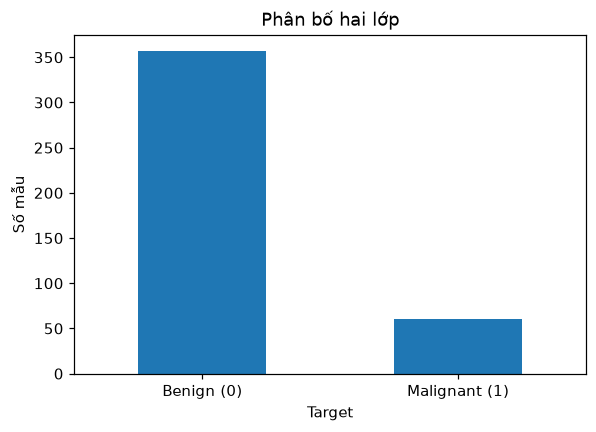

In [6]:
plt.figure(figsize=(6, 4))
class_count.plot(kind="bar")
plt.title("Phân bố hai lớp")
plt.xlabel("Target")
plt.ylabel("Số mẫu")
plt.xticks(
    ticks=[0, 1],
    labels=["Benign (0)", "Malignant (1)"],
    rotation=0
)
plt.show()

In [7]:
display(Markdown(f"**Nhận xét:** benign là lớp đa số ({class_count.loc[0]} mẫu), malignant là lớp thiểu số ({class_count.loc[1]} mẫu). "
                 f"Luôn đoán benign vẫn đúng {class_count.loc[0]/class_count.sum():.2%}, nhưng recall malignant bằng 0. Vì vậy cần thêm Precision, Recall, F1 và AP."))

**Nhận xét:** benign là lớp đa số (357 mẫu), malignant là lớp thiểu số (60 mẫu). Luôn đoán benign vẫn đúng 85.61%, nhưng recall malignant bằng 0. Vì vậy cần thêm Precision, Recall, F1 và AP.

## Bước 5. Kiểm tra thang đo của các feature

Các feature trong dữ liệu có đơn vị và độ lớn khác nhau.

Ví dụ:

- một feature có thể có giá trị khoảng `0.1`;
- feature khác có thể có giá trị hàng trăm hoặc hàng nghìn.

Điều này đặc biệt quan trọng với các thuật toán nhạy với scale, đồng thời ảnh hưởng đến regularization của Logistic Regression.

In [8]:
feature_scale = pd.DataFrame({
    "mean": df.drop(columns="target").mean(),
    "std": df.drop(columns="target").std(),
    "min": df.drop(columns="target").min(),
    "max": df.drop(columns="target").max()
}).sort_values("std", ascending=False)

display(feature_scale.head(10))

,mean,std,min,max
worst area,694.379376,422.448118,185.200,3143.00
mean area,542.766187,260.390089,143.500,1747.00
worst perimeter,95.476595,26.401634,50.410,211.50
area error,28.184887,25.059015,6.802,224.10
mean perimeter,83.851966,19.256076,43.790,155.10
worst texture,24.404436,5.865735,12.020,45.41
mean texture,18.479065,4.184295,9.710,33.81
worst radius,14.587096,3.806504,7.930,30.79
mean radius,12.973859,2.822081,6.981,23.51
perimeter error,2.315299,1.319541,0.757,10.05


In [9]:
display(Markdown(f"**Nhận xét:** độ lệch chuẩn feature lớn nhất là `{feature_scale.index[0]}` "
                 f"({feature_scale.iloc[0]['std']:.4f}), nhỏ nhất {feature_scale['std'].min():.6f}. "
                 "StandardScaler giúp regularization của Logistic Regression và khoảng cách của SMOTE hoạt động trên thang đo phù hợp."))

**Nhận xét:** độ lệch chuẩn feature lớn nhất là `worst area` (422.4481), nhỏ nhất 0.002825. StandardScaler giúp regularization của Logistic Regression và khoảng cách của SMOTE hoạt động trên thang đo phù hợp.

# PHẦN 3. TRAIN/TEST SPLIT

## Bước 6. Tách `X` và `y`

- `X`: các feature đầu vào.
- `y`: nhãn cần dự đoán.

Lưu ý: Không được thực hiện sampling hay chuẩn hóa trước bước chia dữ liệu.

In [10]:
X = df.drop(columns="target")
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (417, 30)
y shape: (417,)


## Bước 7. Train/Test Split với `stratify=y`

Với dữ liệu mất cân bằng, nên sử dụng:

```python
stratify=y
```

để tỷ lệ các lớp trong train và test gần giống tỷ lệ trong dữ liệu ban đầu.

Tập **test được giữ nguyên và không dùng để lựa chọn mô hình**. Các phương án sẽ được so sánh bằng Cross Validation trên tập train.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (333, 30)
Test : (84, 30)


In [12]:
def show_class_ratio(y_data, name):
    count = y_data.value_counts().sort_index()
    ratio = y_data.value_counts(normalize=True).sort_index() * 100

    result = pd.DataFrame({
        "count": count,
        "percent": ratio.round(2)
    })
    result.index = ["Benign (0)", "Malignant (1)"]

    print(name)
    display(result)

show_class_ratio(y_train, "TRAIN")
show_class_ratio(y_test, "TEST")

TRAIN


,count,percent
Benign (0),285,85.59
Malignant (1),48,14.41


TEST


,count,percent
Benign (0),72,85.71
Malignant (1),12,14.29



### Lưu ý  
Không được phép:

- fit `StandardScaler` trên toàn bộ dữ liệu;
- sampling toàn bộ dữ liệu;
- tạo dữ liệu synthetic trước khi chia train/test.

Nếu làm như vậy, thông tin từ test có thể ảnh hưởng đến quá trình training → **data leakage**.

# PHẦN 4. Evaluation

## Bước 8. Tạo bộ metric cho Classification

Các chỉ số đánh giá

- **Accuracy**: tỷ lệ dự đoán đúng tổng thể.
- **Precision**: trong các mẫu dự đoán malignant, bao nhiêu mẫu thật sự malignant.
- **Recall**: trong các mẫu malignant thật, mô hình phát hiện được bao nhiêu.
- **F1-score**: trung bình điều hòa giữa Precision và Recall.
- **ROC-AUC**: khả năng phân biệt hai lớp trên nhiều threshold.
- **PR-AUC / Average Precision**: đặc biệt hữu ích khi lớp dương là minority class.

Độ lệch chuẩn giữa các fold dùng `ddof=1` thống nhất trong toàn bài. Đây là độ phân tán mô tả, không phải khoảng tin cậy độc lập giữa các fold.

In [13]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

## Bước 9. Train một baseline chỉ dự đoán lớp đa số

`DummyClassifier(strategy="most_frequent")` không học quan hệ giữa feature và target. Nó chỉ luôn dự đoán lớp xuất hiện nhiều nhất. Nếu mô hình này vẫn có Accuracy tương đối cao, ta thấy ngay vì sao **Accuracy đơn lẻ có thể gây hiểu nhầm**.

In [14]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

dummy = DummyClassifier(strategy="most_frequent")

dummy_cv = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring
)

dummy_summary = {
    metric: dummy_cv[f"test_{metric}"].mean()
    for metric in scoring.keys()
}

display(pd.Series(dummy_summary, name="Dummy Classifier").round(4))

accuracy     0.8559
precision    0.0000
recall       0.0000
f1           0.0000
roc_auc      0.5000
pr_auc       0.1441
Name: Dummy Classifier, dtype: float64

In [15]:
display(Markdown(f"Dummy đạt Accuracy **{dummy_summary['accuracy']:.2%}**, Recall **{dummy_summary['recall']:.2%}**, "
                 f"F1 **{dummy_summary['f1']:.4f}**, ROC-AUC **{dummy_summary['roc_auc']:.4f}**, AP **{dummy_summary['pr_auc']:.4f}**. "
                 "Accuracy cao ở đây che giấu việc bỏ sót toàn bộ malignant. AP của xác suất hằng bằng tỷ lệ lớp dương trong fold."))

Dummy đạt Accuracy **85.59%**, Recall **0.00%**, F1 **0.0000**, ROC-AUC **0.5000**, AP **0.1441**. Accuracy cao ở đây che giấu việc bỏ sót toàn bộ malignant. AP của xác suất hằng bằng tỷ lệ lớp dương trong fold.

# PHẦN 5. CHUẨN HÓA DỮ LIỆU

## Bước 10. StandardScaler

StandardScaler biến đổi mỗi feature theo công thức:

\[
z = \frac{x - \mu}{\sigma}
\]

Sau chuẩn hóa:

- mean của feature trên tập được fit gần 0;
- standard deviation gần 1.


Logistic Regression mặc định có regularization. Nếu các feature có scale rất khác nhau, regularization có thể tác động không đồng đều lên các hệ số. Ngoài ra, các phương pháp dựa trên khoảng cách như KNN, SVM-RBF hoặc SMOTE càng nhạy với scale.

### Lưu ý 1
Không fit scaler trên toàn bộ dữ liệu

```python
scaler.fit(X)
```

trước khi Cross Validation.

Ta cần đưa scaler vào **Pipeline**:

```text
Training fold
    ↓
StandardScaler.fit()
    ↓
transform()
    ↓
Model.fit()
```

Khi sang fold khác, scaler sẽ được fit lại chỉ bằng training portion của fold đó.

In [16]:
logreg_no_scale = LogisticRegression(
    max_iter=5000,
    random_state=RANDOM_STATE
)

logreg_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

In [17]:
def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring,
        error_score="raise", n_jobs=1
    )

    row = {}
    for metric in scoring.keys():
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)

    return row

scale_compare = pd.DataFrame({
    "Logistic Regression - Raw": cv_summary(
        logreg_no_scale, X_train, y_train, skf
    ),
    "Logistic Regression - StandardScaler": cv_summary(
        logreg_scaled, X_train, y_train, skf
    )
}).T

display(scale_compare.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
Logistic Regression - Raw,0.970,0.0212,0.9278,0.1104,0.8778,0.1301,0.8928,0.0750,0.9789,0.0215,0.9340,0.0615
Logistic Regression - StandardScaler,0.985,0.0183,0.9618,0.0524,0.9400,0.1342,0.9447,0.0722,0.9951,0.0110,0.9855,0.0325


In [18]:
delta = scale_compare.iloc[1] - scale_compare.iloc[0]
display(Markdown(f"**Sau chuẩn hóa:** ΔRecall = {delta['recall_mean']:+.4f}, ΔF1 = {delta['f1_mean']:+.4f}, "
                 f"ΔAP = {delta['pr_auc_mean']:+.4f}. Kết luận dựa trên cùng 5 fold, không chỉ Accuracy."))

**Sau chuẩn hóa:** ΔRecall = +0.0622, ΔF1 = +0.0519, ΔAP = +0.0515. Kết luận dựa trên cùng 5 fold, không chỉ Accuracy.

### Lưu ý 2
Không nên kết luận chỉ dựa vào một metric.

Cần quan sát đồng thời:

- Recall có tăng không?
- F1 có thay đổi không?
- PR-AUC có thay đổi không?
- Standard deviation giữa các fold có lớn không?

# PHẦN 6. K-FOLD CROSS VALIDATION

## Bước 11. Ý tưởng của K-Fold Cross Validation

Với `K = 5`:

1. Chia tập train thành 5 phần.
2. Mỗi lần:
   - dùng 4 phần để train;
   - dùng 1 phần để validation.
3. Lặp lại 5 lần để mỗi phần được dùng làm validation đúng một lần.
4. Lấy trung bình metric của 5 lần.

Nếu metric trên 5 fold lần lượt là:

\[
M_1, M_2, ..., M_K
\]

thì:

\[
\bar{M} = \frac{1}{K}\sum_{i=1}^{K} M_i
\]

Ta cũng quan tâm đến **standard deviation** để xem kết quả có ổn định giữa các fold không.

KFold và StratifiedKFold khác nhau như thế nào?

### `KFold`
Chỉ chia dữ liệu thành K phần, **không đảm bảo tỷ lệ lớp**.

### `StratifiedKFold`
Cố gắng giữ tỷ lệ class trong mỗi fold gần với tỷ lệ của toàn bộ dữ liệu.

Với classification có class imbalance, `StratifiedKFold` thường là lựa chọn phù hợp hơn.

In [19]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [20]:
def get_fold_distribution(cv, X_data, y_data, cv_name):
    rows = []

    for fold, (train_idx, val_idx) in enumerate(cv.split(X_data, y_data), start=1):
        y_fold_train = y_data.iloc[train_idx]
        y_fold_val = y_data.iloc[val_idx]

        rows.append({
            "CV": cv_name,
            "Fold": fold,
            "Train malignant (%)": 100 * y_fold_train.mean(),
            "Validation malignant (%)": 100 * y_fold_val.mean(),
            "Validation size": len(val_idx)
        })

    return pd.DataFrame(rows)

dist_kfold = get_fold_distribution(
    kfold, X_train.reset_index(drop=True), y_train.reset_index(drop=True), "KFold"
)

dist_skfold = get_fold_distribution(
    stratified_kfold,
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True),
    "StratifiedKFold"
)

fold_distribution = pd.concat(
    [dist_kfold, dist_skfold],
    ignore_index=True
)

display(fold_distribution.round(2))

,CV,Fold,Train malignant (%),Validation malignant (%),Validation size
0,KFold,1,15.41,10.45,67
1,KFold,2,14.29,14.93,67
2,KFold,3,13.53,17.91,67
3,KFold,4,13.86,16.67,66
4,KFold,5,14.98,12.12,66
5,StratifiedKFold,1,14.29,14.93,67
6,StratifiedKFold,2,14.29,14.93,67
7,StratifiedKFold,3,14.29,14.93,67
8,StratifiedKFold,4,14.61,13.64,66
9,StratifiedKFold,5,14.61,13.64,66


Ở `StratifiedKFold`, tỷ lệ malignant trong validation folds thường gần nhau hơn.

Điều này giúp việc đánh giá mô hình ổn định hơn, đặc biệt khi minority class có ít mẫu.

## Bước 11b. Cross Validation cho Logistic Regression

Từ đây, ta dùng `StratifiedKFold` làm mặc định.

In [21]:
baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

baseline_cv = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=stratified_kfold,
    scoring=scoring
)

baseline_cv_table = pd.DataFrame({
    metric: baseline_cv[f"test_{metric}"]
    for metric in scoring.keys()
})

baseline_cv_table.index = [
    f"Fold {i}" for i in range(1, len(baseline_cv_table) + 1)
]

display(baseline_cv_table.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc
Fold 1,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
Fold 2,0.9552,1.0000,0.7,0.8235,0.9754,0.9273
Fold 3,0.9851,0.9091,1.0,0.9524,1.0000,1.0000
Fold 4,0.9848,0.9000,1.0,0.9474,1.0000,1.0000
Fold 5,1.0000,1.0000,1.0,1.0000,1.0000,1.0000


In [22]:
weak_fold = baseline_cv_table['recall'].idxmin()
display(Markdown(f"Ở {weak_fold}, Accuracy = {baseline_cv_table.loc[weak_fold, 'accuracy']:.2%} "
                 f"nhưng Recall = {baseline_cv_table.loc[weak_fold, 'recall']:.2%}. Cần xem riêng khả năng phát hiện lớp dương."))

Ở Fold 2, Accuracy = 95.52% nhưng Recall = 70.00%. Cần xem riêng khả năng phát hiện lớp dương.

In [23]:
baseline_cv_result = pd.DataFrame({
    "Mean": baseline_cv_table.mean(),
    "Std": baseline_cv_table.std()
})

display(baseline_cv_result.round(4))

,Mean,Std
accuracy,0.9850,0.0183
precision,0.9618,0.0524
recall,0.9400,0.1342
f1,0.9447,0.0722
roc_auc,0.9951,0.0110
pr_auc,0.9855,0.0325


In [24]:
display(Markdown(f"Recall có trung bình {baseline_cv_result.loc['recall', 'Mean']:.4f}, "
                 f"độ lệch chuẩn {baseline_cv_result.loc['recall', 'Std']:.4f}. Train chỉ có {int(y_train.sum())} malignant, "
                 "mỗi fold validation khoảng 9–10 malignant, nên một vài lỗi cũng làm Recall thay đổi đáng kể."))

Recall có trung bình 0.9400, độ lệch chuẩn 0.1342. Train chỉ có 48 malignant, mỗi fold validation khoảng 9–10 malignant, nên một vài lỗi cũng làm Recall thay đổi đáng kể.

# PHẦN 7. XỬ LÝ CLASS IMBALANCE BẰNG SAMPLING

## Bước 12. Random Over-Sampling

Ý tưởng:

- Giữ nguyên majority class.
- Lấy lặp lại các mẫu minority class cho đến khi đạt tỷ lệ mong muốn.

### Ưu điểm
- Không làm mất mẫu majority.
- Đơn giản, dễ hiểu.

### Nhược điểm
- Có thể lặp lại cùng mẫu nhiều lần.
- Có nguy cơ overfitting minority class.

In [25]:
ros = RandomOverSampler(random_state=RANDOM_STATE)

X_ros_demo, y_ros_demo = ros.fit_resample(X_train, y_train)

print("Trước Random Over-Sampling:")
print(y_train.value_counts().sort_index())

print("\nSau Random Over-Sampling:")
print(pd.Series(y_ros_demo).value_counts().sort_index())

Trước Random Over-Sampling:
target
0    285
1     48
Name: count, dtype: int64

Sau Random Over-Sampling:
target
0    285
1    285
Name: count, dtype: int64


## Bước 13. Random Under-Sampling

Ý tưởng:

- Giữ minority class.
- Loại bớt ngẫu nhiên mẫu của majority class.

### Ưu điểm
- Dataset nhỏ hơn → train nhanh hơn.
- Có thể giảm sự áp đảo của majority class.

### Nhược điểm
- Làm mất dữ liệu thật.
- Có thể bỏ đi các mẫu majority quan trọng.

In [26]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)

X_rus_demo, y_rus_demo = rus.fit_resample(X_train, y_train)

print("Trước Random Under-Sampling:")
print(y_train.value_counts().sort_index())

print("\nSau Random Under-Sampling:")
print(pd.Series(y_rus_demo).value_counts().sort_index())

Trước Random Under-Sampling:
target
0    285
1     48
Name: count, dtype: int64

Sau Random Under-Sampling:
target
0    48
1    48
Name: count, dtype: int64


## Bước 14. SMOTE

SMOTE không chỉ sao chép mẫu minority.

Nó tạo các mẫu tổng hợp mới dựa trên các mẫu minority lân cận.

Điểm cần nhớ:

- SMOTE dựa trên khoảng cách.
- Vì vậy scale của feature rất quan trọng.
- Trong quy trình đúng, nên để `StandardScaler` và `SMOTE` bên trong cùng một Pipeline.

Ta chỉ minh họa số lượng mẫu ở đây; phần huấn luyện chính thức sẽ dùng Pipeline.

In [27]:
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)

smote_demo = SMOTE(random_state=RANDOM_STATE)

X_smote_demo, y_smote_demo = smote_demo.fit_resample(
    X_train_scaled_demo,
    y_train
)

print("Trước SMOTE:")
print(y_train.value_counts().sort_index())

print("\nSau SMOTE:")
print(pd.Series(y_smote_demo).value_counts().sort_index())

Trước SMOTE:
target
0    285
1     48
Name: count, dtype: int64

Sau SMOTE:
target
0    285
1    285
Name: count, dtype: int64


# PHẦN 8. PIPELINE ĐÚNG CÁCH: SCALE + SAMPLE + MODEL

Tại sao sampling phải nằm trong Pipeline?

Giả sử ta sampling toàn bộ `X_train` trước rồi mới Cross Validation.

Khi đó một mẫu được tạo hoặc sao chép từ dữ liệu có thể ảnh hưởng gián tiếp đến cả training fold và validation fold.

Kết quả CV có thể **quá lạc quan**.

Quy trình đúng cho mỗi fold:

```text
Training portion của fold
        ↓
StandardScaler.fit_transform()
        ↓
Sampling.fit_resample()
        ↓
LogisticRegression.fit()
        ↓
Validation portion
        ↓
StandardScaler.transform()
        ↓
Model.predict()
```

Validation data **không được sampling**.

## Bước 15. Xây dựng các Pipeline để so sánh

Ta giữ cùng một classifier để chỉ thay đổi chiến lược xử lý imbalance:

1. Không sampling.
2. Random Over-Sampling.
3. Random Under-Sampling.
4. SMOTE.

In [28]:
models = {
    "No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random OverSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random UnderSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])
}

## Bước 16. Đánh giá các phương án bằng Stratified K-Fold

Tất cả mô hình được đánh giá trên **cùng các folds** để so sánh công bằng.

In [29]:
all_results = []

for name, model in models.items():
    result = cv_summary(
        model,
        X_train,
        y_train,
        stratified_kfold
    )
    result["model"] = name
    all_results.append(result)

cv_comparison = pd.DataFrame(all_results).set_index("model")

display(cv_comparison.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
model,,,,,,,,,,,,
No Sampling,0.9850,0.0183,0.9618,0.0524,0.94,0.1342,0.9447,0.0722,0.9951,0.0110,0.9855,0.0325
Random OverSampling,0.9850,0.0106,0.9418,0.0532,0.96,0.0894,0.9472,0.0394,0.9951,0.0110,0.9855,0.0325
Random UnderSampling,0.9849,0.0107,0.9255,0.0767,0.98,0.0447,0.9494,0.0354,0.9961,0.0086,0.9895,0.0234
SMOTE,0.9880,0.0125,0.9618,0.0524,0.96,0.0894,0.9577,0.0460,0.9947,0.0108,0.9836,0.0318


Với dữ liệu imbalance, không nên chỉ nhìn Accuracy.

Ta tập trung nhiều hơn vào:

- Recall;
- F1;
- PR-AUC;
- đồng thời vẫn xem Precision và ROC-AUC.

In [30]:
comparison_short = cv_comparison[
    [
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
        "roc_auc_mean",
        "pr_auc_mean"
    ]
].copy()

display(
    comparison_short.sort_values(
        "f1_mean",
        ascending=False
    ).round(4)
)

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
model,,,,,,
SMOTE,0.9880,0.9618,0.96,0.9577,0.9947,0.9836
Random UnderSampling,0.9849,0.9255,0.98,0.9494,0.9961,0.9895
Random OverSampling,0.9850,0.9418,0.96,0.9472,0.9951,0.9855
No Sampling,0.9850,0.9618,0.94,0.9447,0.9951,0.9855


In [31]:
save_table(cv_comparison, 'vi_du_sampling_cv')
winner = cv_comparison['f1_mean'].idxmax()
recall_winner = cv_comparison['recall_mean'].idxmax()
display(Markdown(f"**Theo CV:** {winner} có F1 trung bình cao nhất ({cv_comparison.loc[winner, 'f1_mean']:.4f}). "
                 f"{recall_winner} có Recall cao nhất ({cv_comparison.loc[recall_winner, 'recall_mean']:.4f}). "
                 "Cần đối chiếu Precision và độ phân tán; chênh lệch trên tập nhỏ chưa chứng minh một kỹ thuật luôn tốt hơn."))

**Theo CV:** SMOTE có F1 trung bình cao nhất (0.9577). Random UnderSampling có Recall cao nhất (0.9800). Cần đối chiếu Precision và độ phân tán; chênh lệch trên tập nhỏ chưa chứng minh một kỹ thuật luôn tốt hơn.

**Lưu ý**: Với dữ liệu imbalance, không nên chỉ nhìn Accuracy.

Cần tập trung nhiều hơn vào:

- Recall;
- F1;
- PR-AUC;
- đồng thời vẫn xem Precision và ROC-AUC.

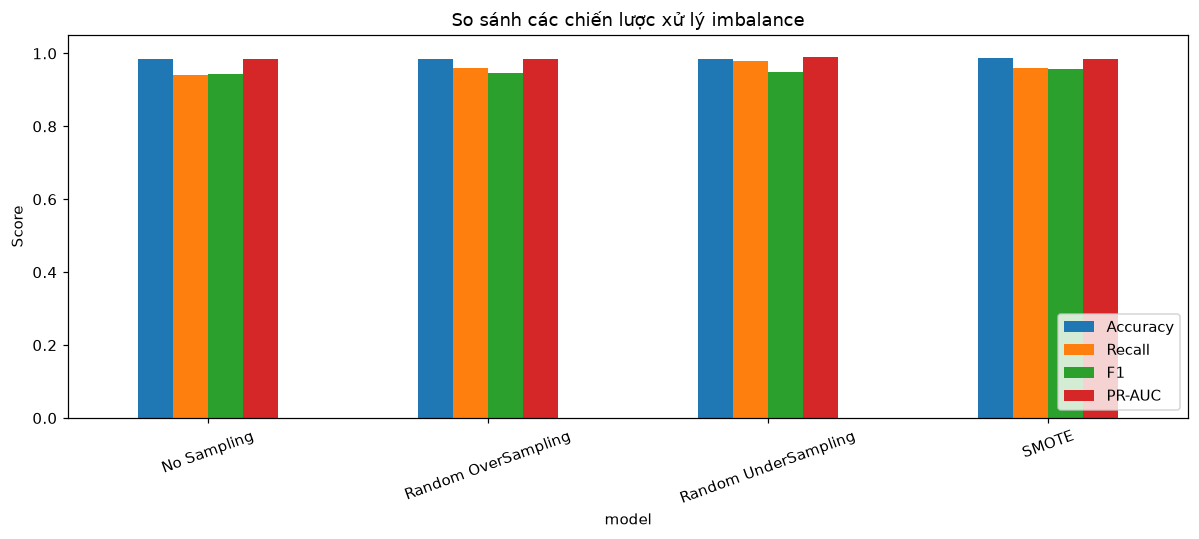

In [32]:
plot_data = comparison_short[
    [
        "accuracy_mean",
        "recall_mean",
        "f1_mean",
        "pr_auc_mean"
    ]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("So sánh các chiến lược xử lý imbalance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(
    ["Accuracy", "Recall", "F1", "PR-AUC"],
    loc="lower right"
)
plt.tight_layout()
plt.show()

In [33]:
display(Markdown(f"Accuracy các phương án nằm trong khoảng {cv_comparison['accuracy_mean'].min():.2%}–"
                 f"{cv_comparison['accuracy_mean'].max():.2%}. Biểu đồ cho thấy cần quan sát thêm Recall, F1 và AP để so sánh hiệu quả trên lớp thiểu số."))

Accuracy các phương án nằm trong khoảng 98.49%–98.80%. Biểu đồ cho thấy cần quan sát thêm Recall, F1 và AP để so sánh hiệu quả trên lớp thiểu số.

Phân tích kết quả

Không có một kỹ thuật sampling luôn tốt nhất cho mọi bài toán.

Ví dụ:

- Over-sampling có thể làm Recall tăng nhưng Precision giảm.
- Under-sampling có thể làm mất thông tin của majority class.
- SMOTE có thể cải thiện minority class nhưng hiệu quả phụ thuộc cấu trúc dữ liệu.
- Không sampling đôi khi vẫn tốt nếu mô hình đã phân tách lớp tốt.

Điều quan trọng là **chọn metric phù hợp với mục tiêu của bài toán**.

# PHẦN 9. CHỌN MÔ HÌNH VÀ ĐÁNH GIÁ TRÊN TẬP TEST

## Bước 17. Chọn tiêu chí

Trong ví dụ này, ta minh họa việc chọn phương án có **F1 trung bình cao nhất trên Cross Validation**.

Có thể thay bằng:

- `recall_mean` nếu bỏ sót lớp dương là rất nghiêm trọng;
- `pr_auc_mean` nếu muốn đánh giá tốt hơn trong bối cảnh class imbalance;
- hoặc một tiêu chí nghiệp vụ riêng.

**Không chọn mô hình bằng kết quả trên tập test.**

In [34]:
selection_metric = "f1_mean"

best_name = cv_comparison[selection_metric].idxmax()
best_model = models[best_name]

print("Tiêu chí lựa chọn:", selection_metric)
print("Pipeline được chọn:", best_name)
print(
    "CV score:",
    round(cv_comparison.loc[best_name, selection_metric], 4)
)

Tiêu chí lựa chọn: f1_mean
Pipeline được chọn: SMOTE
CV score: 0.9577


## Bước 18. Fit lại trên toàn bộ tập train

Sau khi đã chọn pipeline bằng CV, ta huấn luyện pipeline đó trên **toàn bộ tập train**.

In [35]:
best_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Bước 19. Đánh giá một lần trên tập test

Tập test đóng vai trò mô phỏng dữ liệu chưa từng thấy.

Ta tính:

- Accuracy;
- Precision;
- Recall;
- F1;
- ROC-AUC;
- PR-AUC.

In [36]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob)
}, name="Test score")

display(test_metrics.round(4))

Accuracy     0.9762
Precision    0.9167
Recall       0.9167
F1           0.9167
ROC-AUC      0.9988
PR-AUC       0.9936
Name: Test score, dtype: float64

In [37]:
save_table(test_metrics, 'vi_du_test_metrics')
save_table(pd.DataFrame({'y_true': y_test, 'y_pred': y_pred, 'p_malignant': y_prob}), 'vi_du_test_du_doan')
display(Markdown(f"**Test độc lập ({len(y_test)} mẫu, {int(y_test.sum())} malignant):** Accuracy {test_metrics['Accuracy']:.2%}, "
                 f"Precision {test_metrics['Precision']:.2%}, Recall {test_metrics['Recall']:.2%}, F1 {test_metrics['F1']:.4f}. "
                 "Ngưỡng mặc định là 0.5. Không điều chỉnh mô hình/ngưỡng theo kết quả test này."))

**Test độc lập (84 mẫu, 12 malignant):** Accuracy 97.62%, Precision 91.67%, Recall 91.67%, F1 0.9167. Ngưỡng mặc định là 0.5. Không điều chỉnh mô hình/ngưỡng theo kết quả test này.

## Bước 20. Confusion Matrix

Với quy ước:

- `0 = benign`
- `1 = malignant`

Confusion Matrix giúp ta phân tích:

- True Negative;
- False Positive;
- False Negative;
- True Positive.

Trong nhiều bài toán phát hiện rủi ro, **False Negative** là loại lỗi cần đặc biệt chú ý.

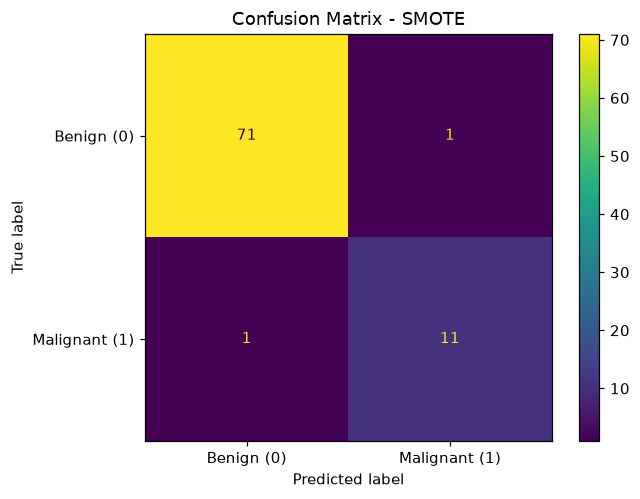

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Benign (0)", "Malignant (1)"]
)

plt.title(f"Confusion Matrix - {best_name}")
plt.show()

In [39]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
display(Markdown(f"**Ma trận nhầm lẫn:** TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}. "
                 f"Mô hình bỏ sót {fn}/{fn+tp} malignant. Test chỉ có {fn+tp} malignant nên một lỗi làm Recall thay đổi {1/(fn+tp):.2%}."))

**Ma trận nhầm lẫn:** TN = 71, FP = 1, FN = 1, TP = 11. Mô hình bỏ sót 1/12 malignant. Test chỉ có 12 malignant nên một lỗi làm Recall thay đổi 8.33%.

## Bước 21. Classification Report

In [40]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign (0)", "Malignant (1)"],
        digits=4,
        zero_division=0
    )
)

               precision    recall  f1-score   support

   Benign (0)     0.9861    0.9861    0.9861        72
Malignant (1)     0.9167    0.9167    0.9167        12

     accuracy                         0.9762        84
    macro avg     0.9514    0.9514    0.9514        84
 weighted avg     0.9762    0.9762    0.9762        84



### Cách đọc
Mỗi class có:

- precision

- recall

- f1-score

- support: số mẫu thật của class.

Ngoài ra cần chú ý:

- macro avg: trung bình hai class với trọng số bằng nhau.

- weighted avg: trung bình có trọng số theo số lượng mẫu từng class.

Với dữ liệu mất cân bằng, nên chú ý macro avg và metric của minority class thay vì chỉ nhìn weighted avg.

In [41]:
report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
display(Markdown(f"Weighted F1 = {report['weighted avg']['f1-score']:.4f}, Macro F1 = {report['macro avg']['f1-score']:.4f}. "
                 "Macro cho hai lớp trọng số bằng nhau; weighted chịu ảnh hưởng mạnh hơn của lớp benign đông mẫu."))

Weighted F1 = 0.9762, Macro F1 = 0.9514. Macro cho hai lớp trọng số bằng nhau; weighted chịu ảnh hưởng mạnh hơn của lớp benign đông mẫu.

## Bước 22. Precision-Recall Curve

Khi positive class hiếm, Precision-Recall Curve thường hữu ích hơn việc chỉ nhìn Accuracy.

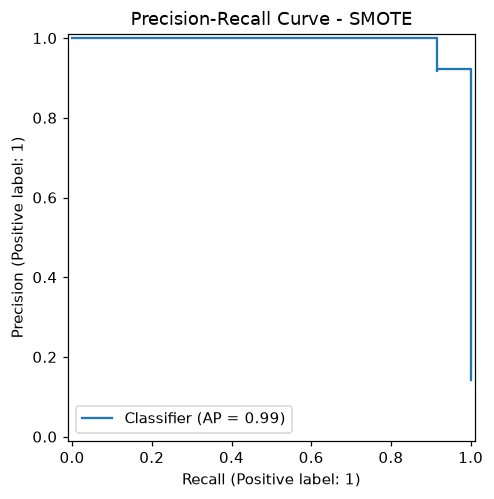

In [42]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(f"Precision-Recall Curve - {best_name}")
plt.show()

### Cách đọc
- Trục X: Recall.

- Trục Y: Precision.

Mỗi điểm trên đường cong tương ứng với một classification threshold khác nhau.

Một mô hình tốt có thể duy trì Precision cao trong khi Recall vẫn cao.

Bài dùng Average Precision (AP) để tóm tắt đường Precision–Recall: trung bình precision có trọng số theo mức tăng recall. AP và diện tích tính bằng quy tắc hình thang có thể khác nhau.

In [43]:
display(Markdown(f"Test AP = **{test_metrics['PR-AUC']:.4f}**, so với mốc tỷ lệ dương {y_test.mean():.4f}. "
                 "Đường cong mô tả nhiều ngưỡng; nó không thay thế Recall tại ngưỡng đang sử dụng. Không dùng test để chọn ngưỡng mới."))

Test AP = **0.9936**, so với mốc tỷ lệ dương 0.1429. Đường cong mô tả nhiều ngưỡng; nó không thay thế Recall tại ngưỡng đang sử dụng. Không dùng test để chọn ngưỡng mới.

# PHẦN 10. PIPELINE CHUNG

Quy trình chuẩn trong bài này:

```text
1. Nạp dữ liệu
        ↓
2. Kiểm tra class distribution
        ↓
3. Tách X và y
        ↓
4. Train/Test Split với stratify=y
        ↓
5. Giữ nguyên tập test
        ↓
6. Xây Pipeline:
   StandardScaler
        ↓
   Sampling
        ↓
   Classifier
        ↓
7. Stratified K-Fold Cross Validation trên tập train
        ↓
8. So sánh Accuracy / Precision / Recall / F1 / ROC-AUC / PR-AUC
        ↓
9. Chọn phương án theo metric phù hợp
        ↓
10. Fit lại trên toàn bộ train
        ↓
11. Đánh giá một lần trên test
```

## Những lỗi cần tránh

### Lỗi 1. Chỉ nhìn Accuracy
Một mô hình luôn dự đoán majority class vẫn có thể có Accuracy cao.

### Lỗi 2. Chuẩn hóa trước khi chia dữ liệu
`StandardScaler.fit()` trên toàn bộ dataset gây leakage.

### Lỗi 3. Sampling trước Train/Test Split
Các mẫu được sao chép hoặc tạo mới có thể làm test không còn độc lập.

### Lỗi 4. Sampling validation/test
Sampling chỉ được áp dụng lên phần training.

### Lỗi 5. Sampling toàn bộ train trước Cross Validation
Sampling phải được thực hiện **bên trong từng fold**, tốt nhất bằng `imblearn.Pipeline`.

### Lỗi 6. Dùng KFold thông thường mà không để ý tỷ lệ lớp
Với dữ liệu imbalance, ưu tiên `StratifiedKFold`.

# PHẦN 11. BÀI TẬP THỰC HÀNH

### Bài 1 — Mức độ imbalance
Thay số mẫu malignant từ `60` thành:

- `40`;
- `120`;
- toàn bộ dữ liệu gốc.

So sánh Accuracy, Recall, F1 và PR-AUC.

---

### Bài 2 — KFold và StratifiedKFold
Dùng cùng Logistic Regression và so sánh:

- mean score;
- standard deviation giữa các fold.

Giải thích tại sao `StratifiedKFold` thường ổn định hơn với dữ liệu imbalance.

---

### Bài 3 — Thay đổi số fold
Lần lượt dùng:

- `K = 3`;
- `K = 5`;
- `K = 10`.

Quan sát sự thay đổi của mean và standard deviation.

---

### Bài 4 — Thay đổi mức Over-Sampling
Thử:

```python
RandomOverSampler(sampling_strategy=0.5)
RandomOverSampler(sampling_strategy=0.75)
RandomOverSampler(sampling_strategy=1.0)
```

Giải thích trade-off giữa Precision và Recall.

---

### Bài 5 — So sánh ba kỹ thuật sampling
So sánh:

- Random Over-Sampling;
- Random Under-Sampling;
- SMOTE.

Không chỉ chọn kỹ thuật có Accuracy cao nhất. Hãy giải thích bằng Precision, Recall, F1 và PR-AUC.

---

### Bài 6 — Thay classifier
Giữ nguyên quy trình preprocessing và sampling, thay Logistic Regression bằng:

- KNN;
- SVM;
- Decision Tree.

Phân tích mô hình nào nhạy với StandardScaler hơn.

---

### Bài 7 — Câu hỏi suy luận
Trả lời ngắn:

1. Tại sao không nên sampling tập test?
2. Tại sao không nên fit StandardScaler trên toàn bộ dữ liệu?
3. Khi nào Recall quan trọng hơn Precision?
4. Khi nào Precision quan trọng hơn Recall?
5. Vì sao PR-AUC thường hữu ích với dữ liệu imbalance?
6. Vì sao `StratifiedKFold` phù hợp hơn `KFold` trong bài này?
7. Random Under-Sampling có thể làm mất thông tin như thế nào?
8. SMOTE khác Random Over-Sampling ở điểm nào?

## Lời giải Phần 11 — Thiết kế thí nghiệm
Các thí nghiệm dưới đây chỉ dùng train/CV. Trừ Bài 1 thay kích thước dữ liệu,
các bài dùng chung `X_train`, `y_train` từ ví dụ để so sánh công bằng.
Mỗi pipeline fit scaler và sampler riêng trong training fold. Không tái sử dụng dữ liệu demo đã sampling.
Các bảng đều lưu vào `ket_qua/`; `std` là độ lệch chuẩn mẫu (`ddof=1`).

In [44]:
def make_binary_pipeline(classifier=None, sampler=None, scaled=True):
    if classifier is None:
        classifier = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    steps = []
    if scaled:
        steps.append(("scaler", StandardScaler()))
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("model", clone(classifier)))
    return ImbPipeline(steps)

def compare_configs(configs, X_data, y_data, cv):
    rows = []
    for name, pipeline in configs.items():
        rows.append({"config": name, **cv_summary(pipeline, X_data, y_data, cv)})
    return pd.DataFrame(rows).set_index("config")

samplers = {
    "No Sampling": None,
    "ROS": RandomOverSampler(random_state=RANDOM_STATE),
    "RUS": RandomUnderSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
}
main_columns = [f"{m}_{s}" for m in ["accuracy", "precision", "recall", "f1", "pr_auc"] for s in ["mean", "std"]]

### Bài 1 — Thay đổi mức mất cân bằng
Lần lượt giữ 40, 60 (mốc), 120 và toàn bộ 212 malignant, luôn giữ 357 benign.
Mỗi bộ chia train/test 80/20 có stratify, so sánh 4 chiến lược bằng 5-fold CV trên train.
**Không dùng test trong thí nghiệm này.** Tỷ lệ dương thay đổi nên AP giữa các bộ
có mốc nền khác nhau. Thành phần mẫu và kích thước train cũng thay đổi, không thể quy mọi khác biệt chỉ cho imbalance.

,n_malignant,config,positive_rate_train,dummy_accuracy,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
0,40,No Sampling,0.1009,0.8991,0.9938,0.0086,1.0000,0.0000,0.9429,0.0782,0.9692,0.0421,0.9754,0.0363
1,40,ROS,0.1009,0.8991,0.9780,0.0237,0.9333,0.1491,0.8762,0.0702,0.8983,0.0911,0.9524,0.0347
2,40,RUS,0.1009,0.8991,0.9716,0.0206,0.8333,0.1559,0.9429,0.0782,0.8760,0.0859,0.9629,0.0508
3,40,SMOTE,0.1009,0.8991,0.9906,0.0086,1.0000,0.0000,0.9095,0.0832,0.9510,0.0450,0.9707,0.0404
4,60,No Sampling,0.1441,0.8559,0.9850,0.0183,0.9618,0.0524,0.9400,0.1342,0.9447,0.0722,0.9855,0.0325
5,60,ROS,0.1441,0.8559,0.9850,0.0106,0.9418,0.0532,0.9600,0.0894,0.9472,0.0394,0.9855,0.0325
6,60,RUS,0.1441,0.8559,0.9849,0.0107,0.9255,0.0767,0.9800,0.0447,0.9494,0.0354,0.9895,0.0234
7,60,SMOTE,0.1441,0.8559,0.9880,0.0125,0.9618,0.0524,0.9600,0.0894,0.9577,0.0460,0.9836,0.0318
8,120,No Sampling,0.2520,0.7480,0.9711,0.0216,0.9636,0.0813,0.9274,0.0274,0.9432,0.0388,0.9882,0.0147
9,120,ROS,0.2520,0.7480,0.9738,0.0309,0.9465,0.0942,0.9584,0.0233,0.9506,0.0552,0.9865,0.0164


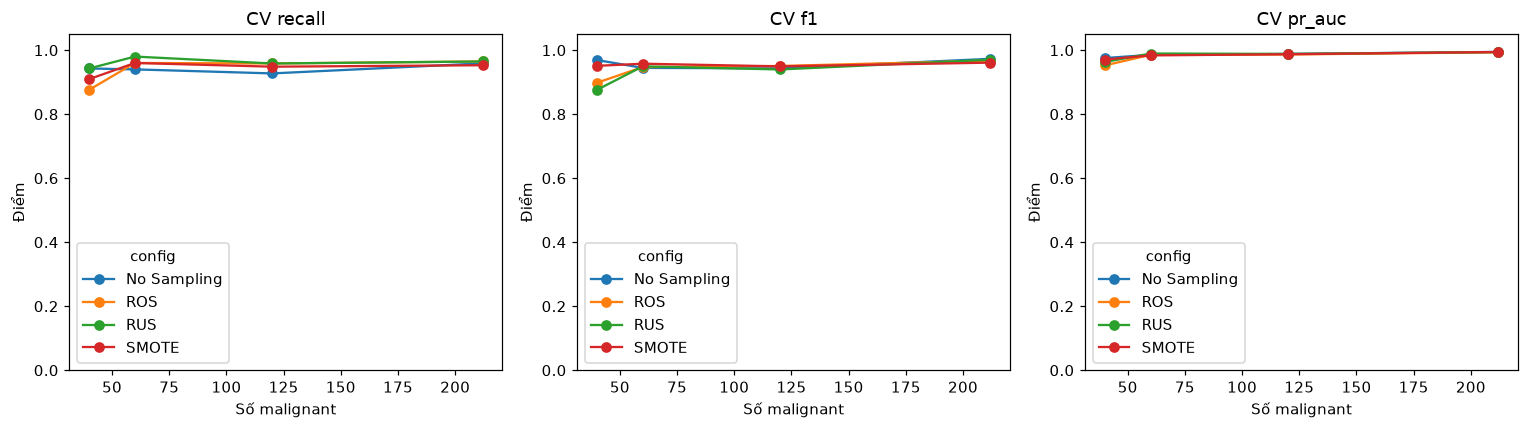

- **40 malignant:** phương án F1 cao nhất là No Sampling, Accuracy 0.9938, Recall 0.9429, F1 0.9692, AP 0.9754.

- **60 malignant:** phương án F1 cao nhất là SMOTE, Accuracy 0.9880, Recall 0.9600, F1 0.9577, AP 0.9836.

- **120 malignant:** phương án F1 cao nhất là ROS, Accuracy 0.9738, Recall 0.9584, F1 0.9506, AP 0.9865.

- **212 malignant:** phương án F1 cao nhất là No Sampling, Accuracy 0.9802, Recall 0.9588, F1 0.9730, AP 0.9946.

Khi tỷ lệ malignant tăng, Accuracy của Dummy giảm. Mô hình học từ nhiều malignant hơn có thể cải thiện, nhưng xu hướng từng metric không bắt buộc đơn điệu. Cần xem cả std và mốc AP bằng tỷ lệ lớp dương.

In [45]:
b1_tables = []
for n_malignant in [40, 60, 120, int(y_full.sum())]:
    positives = df_full[df_full.target == 1].sample(n=n_malignant, random_state=RANDOM_STATE)
    variant = pd.concat([df_full[df_full.target == 0], positives]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    xa, _, ya, _ = train_test_split(variant.drop(columns="target"), variant.target,
                                   test_size=0.2, stratify=variant.target, random_state=RANDOM_STATE)
    configs = {name: make_binary_pipeline(sampler=sampler) for name, sampler in samplers.items()}
    result = compare_configs(configs, xa, ya, skf).reset_index()
    result.insert(0, "n_malignant", n_malignant)
    result["total"] = len(variant)
    result["positive_rate_train"] = ya.mean()
    result["dummy_accuracy"] = 1 - ya.mean()
    b1_tables.append(result)
b1 = pd.concat(b1_tables, ignore_index=True)
save_table(b1, "bai1_muc_imbalance")
display(b1[["n_malignant", "config", "positive_rate_train", "dummy_accuracy"] + main_columns].round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["recall", "f1", "pr_auc"]):
    b1.pivot(index="n_malignant", columns="config", values=f"{metric}_mean").plot(marker="o", ax=ax)
    ax.set(title=f"CV {metric}", xlabel="Số malignant", ylabel="Điểm", ylim=(0, 1.05))
plt.tight_layout()
plt.show()
for n, group in b1.groupby("n_malignant"):
    row = group.loc[group.f1_mean.idxmax()]
    display(Markdown(f"- **{n} malignant:** phương án F1 cao nhất là {row['config']}, "
                     f"Accuracy {row.accuracy_mean:.4f}, Recall {row.recall_mean:.4f}, F1 {row.f1_mean:.4f}, AP {row.pr_auc_mean:.4f}."))
display(Markdown("Khi tỷ lệ malignant tăng, Accuracy của Dummy giảm. Mô hình học từ nhiều malignant hơn có thể cải thiện, "
                 "nhưng xu hướng từng metric không bắt buộc đơn điệu. Cần xem cả std và mốc AP bằng tỷ lệ lớp dương."))

### Bài 2 — KFold so với StratifiedKFold
Cùng Logistic Regression + StandardScaler, cùng seed, cùng 5 fold.
StratifiedKFold kiểm soát tỷ lệ lớp trong validation; điều này không bảo đảm std của mọi metric luôn thấp hơn trong một lần chia.

In [46]:
b2 = pd.DataFrame({
    "KFold": cv_summary(make_binary_pipeline(), X_train, y_train, kfold),
    "StratifiedKFold": cv_summary(make_binary_pipeline(), X_train, y_train, stratified_kfold),
}).T
save_table(b2, "bai2_kfold_vs_stratified")
save_table(fold_distribution, "bai2_ty_le_lop_tung_fold")
display(b2.round(4))
display(fold_distribution.round(2))
display(Markdown(f"Recall std: KFold **{b2.loc['KFold', 'recall_std']:.4f}**, "
                 f"StratifiedKFold **{b2.loc['StratifiedKFold', 'recall_std']:.4f}**. "
                 "Stratification giữ số malignant ở mỗi fold gần nhau, hạn chế fold có quá ít hoặc không có lớp dương. "
                 "Độ khó của từng mẫu vẫn khác nhau nên std thực nghiệm có thể tăng hoặc giảm."))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
KFold,0.988,0.0125,1.0000,0.0000,0.9012,0.1177,0.9446,0.0685,0.9975,0.0047,0.9891,0.0210
StratifiedKFold,0.985,0.0183,0.9618,0.0524,0.9400,0.1342,0.9447,0.0722,0.9951,0.0110,0.9855,0.0325


,CV,Fold,Train malignant (%),Validation malignant (%),Validation size
0,KFold,1,15.41,10.45,67
1,KFold,2,14.29,14.93,67
2,KFold,3,13.53,17.91,67
3,KFold,4,13.86,16.67,66
4,KFold,5,14.98,12.12,66
5,StratifiedKFold,1,14.29,14.93,67
6,StratifiedKFold,2,14.29,14.93,67
7,StratifiedKFold,3,14.29,14.93,67
8,StratifiedKFold,4,14.61,13.64,66
9,StratifiedKFold,5,14.61,13.64,66


Recall std: KFold **0.1177**, StratifiedKFold **0.1342**. Stratification giữ số malignant ở mỗi fold gần nhau, hạn chế fold có quá ít hoặc không có lớp dương. Độ khó của từng mẫu vẫn khác nhau nên std thực nghiệm có thể tăng hoặc giảm.

### Bài 3 — K = 3, 5, 7, 10
Bổ sung K=7 theo nội dung cần ôn trong ảnh. Giữ Logistic Regression + StandardScaler, không sampling. K lớn làm training portion lớn hơn,
nhưng validation ít mẫu hơn. Với 48 malignant ở train, K = 10 chỉ còn khoảng 4–5 malignant mỗi validation fold.
Không dùng test để chọn K.

In [47]:
b3 = pd.DataFrame({k: cv_summary(make_binary_pipeline(), X_train, y_train,
                               StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE))
                   for k in [3, 5, 7, 10]}).T
b3.index.name = "K"
save_table(b3, "bai3_so_fold")
display(b3.round(4))
for k, row in b3.iterrows():
    display(Markdown(f"- **K={k}:** Recall {row.recall_mean:.4f} ± {row.recall_std:.4f}, "
                     f"F1 {row.f1_mean:.4f} ± {row.f1_std:.4f}, AP {row.pr_auc_mean:.4f} ± {row.pr_auc_std:.4f}."))
display(Markdown("K lớn tăng số lần fit và khiến metric từng fold nhạy hơn với một lỗi. "
                 "Vì kích thước validation khác nhau, không xem std thấp nhất là bằng chứng K tốt nhất. K=5 là lựa chọn thực hành hợp lý cho dữ liệu này."))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
K,,,,,,,,,,,,
3,0.988,0.0052,1.0000,0.0000,0.9167,0.0361,0.9563,0.0199,0.9971,0.0049,0.9907,0.0162
5,0.985,0.0183,0.9618,0.0524,0.9400,0.1342,0.9447,0.0722,0.9951,0.0110,0.9855,0.0325
7,0.988,0.0164,0.9796,0.0540,0.9388,0.1124,0.9542,0.0645,0.9955,0.0119,0.9885,0.0304
10,0.988,0.0155,0.9667,0.0703,0.9550,0.0956,0.9564,0.0580,0.9957,0.0136,0.9861,0.0439


- **K=3:** Recall 0.9167 ± 0.0361, F1 0.9563 ± 0.0199, AP 0.9907 ± 0.0162.

- **K=5:** Recall 0.9400 ± 0.1342, F1 0.9447 ± 0.0722, AP 0.9855 ± 0.0325.

- **K=7:** Recall 0.9388 ± 0.1124, F1 0.9542 ± 0.0645, AP 0.9885 ± 0.0304.

- **K=10:** Recall 0.9550 ± 0.0956, F1 0.9564 ± 0.0580, AP 0.9861 ± 0.0439.

K lớn tăng số lần fit và khiến metric từng fold nhạy hơn với một lỗi. Vì kích thước validation khác nhau, không xem std thấp nhất là bằng chứng K tốt nhất. K=5 là lựa chọn thực hành hợp lý cho dữ liệu này.

### Bài 4 — Mức Random Over-Sampling
`sampling_strategy` nhị phân là tỷ số **số mẫu minority / số mẫu majority sau sampling**.
Thử 0.5, 0.75, 1.0 trên cùng CV; đối chiếu mốc không sampling.

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
config,,,,,,,,,,
No Sampling,0.985,0.0183,0.9618,0.0524,0.94,0.1342,0.9447,0.0722,0.9855,0.0325
ROS 0.5,0.988,0.0125,0.9618,0.0524,0.96,0.0894,0.9577,0.0460,0.9836,0.0318
ROS 0.75,0.988,0.0125,0.9618,0.0524,0.96,0.0894,0.9577,0.0460,0.9855,0.0325
ROS 1.0,0.985,0.0106,0.9418,0.0532,0.96,0.0894,0.9472,0.0394,0.9855,0.0325


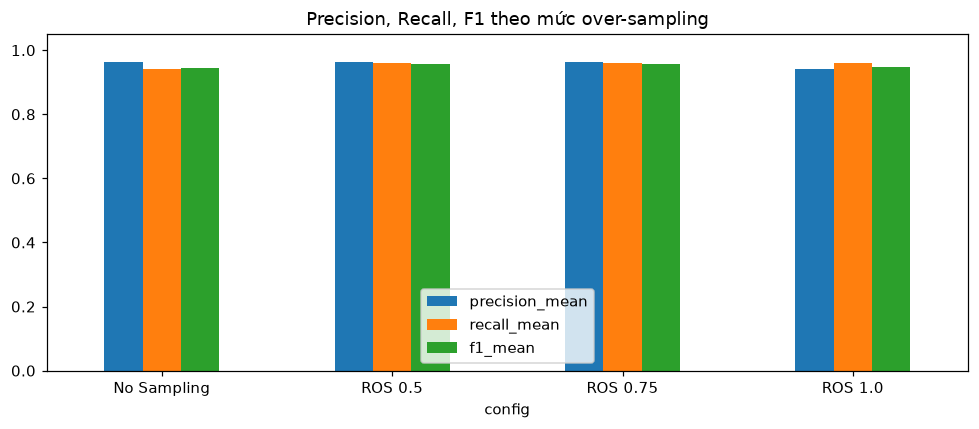

- **No Sampling:** Precision 0.9618, Recall 0.9400, F1 0.9447.

- **ROS 0.5:** Precision 0.9618, Recall 0.9600, F1 0.9577.

- **ROS 0.75:** Precision 0.9618, Recall 0.9600, F1 0.9577.

- **ROS 1.0:** Precision 0.9418, Recall 0.9600, F1 0.9472.

Tăng tỷ trọng malignant khiến classifier chú ý lớp dương hơn, có thể tăng Recall nhưng tạo thêm FP và giảm Precision. Xu hướng không bắt buộc đơn điệu vì ROS lấy mẫu ngẫu nhiên và dữ liệu ít. Chọn mức theo CV và chi phí FP/FN, không mặc định tỷ lệ 1.0 tốt nhất.

In [48]:
configs_b4 = {"No Sampling": make_binary_pipeline()}
for ratio in [0.5, 0.75, 1.0]:
    configs_b4[f"ROS {ratio}"] = make_binary_pipeline(sampler=RandomOverSampler(sampling_strategy=ratio, random_state=RANDOM_STATE))
b4 = compare_configs(configs_b4, X_train, y_train, skf)
save_table(b4, "bai4_muc_oversampling")
display(b4[main_columns].round(4))
b4[["precision_mean", "recall_mean", "f1_mean"]].plot.bar(figsize=(9, 4), ylim=(0, 1.05), rot=0)
plt.title("Precision, Recall, F1 theo mức over-sampling")
plt.tight_layout()
plt.show()
for name, row in b4.iterrows():
    display(Markdown(f"- **{name}:** Precision {row.precision_mean:.4f}, Recall {row.recall_mean:.4f}, F1 {row.f1_mean:.4f}."))
display(Markdown("Tăng tỷ trọng malignant khiến classifier chú ý lớp dương hơn, có thể tăng Recall nhưng tạo thêm FP và giảm Precision. "
                 "Xu hướng không bắt buộc đơn điệu vì ROS lấy mẫu ngẫu nhiên và dữ liệu ít. Chọn mức theo CV và chi phí FP/FN, không mặc định tỷ lệ 1.0 tốt nhất."))

### Bài 5 — So sánh ROS, RUS và SMOTE
Dùng lại đúng bảng CV ở ví dụ, tránh chạy lại cùng thí nghiệm. Mốc không sampling giúp xác định
sampling có cải thiện hay không. Chọn theo F1 CV như đã quy định trước khi xem test.

In [49]:
b5 = cv_comparison.copy()
save_table(b5, "bai5_ba_ky_thuat_sampling")
display(b5[main_columns].sort_values("f1_mean", ascending=False).round(4))
for name, row in b5.iterrows():
    display(Markdown(f"- **{name}:** Precision {row.precision_mean:.4f}, Recall {row.recall_mean:.4f}, "
                     f"F1 {row.f1_mean:.4f} ± {row.f1_std:.4f}, AP {row.pr_auc_mean:.4f}."))
display(Markdown(f"**Kết luận theo tiêu chí F1:** chọn {b5.f1_mean.idxmax()} trong các phương án này. "
                 "ROS giữ dữ liệu majority nhưng lặp minority; RUS bỏ bớt majority nên có thể mất vùng biên quan trọng; "
                 "SMOTE nội suy minority nhưng có thể tạo mẫu trong vùng chồng lấn. Không suy rộng thứ hạng từ một bộ dữ liệu nhỏ."))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
model,,,,,,,,,,
SMOTE,0.9880,0.0125,0.9618,0.0524,0.96,0.0894,0.9577,0.0460,0.9836,0.0318
Random UnderSampling,0.9849,0.0107,0.9255,0.0767,0.98,0.0447,0.9494,0.0354,0.9895,0.0234
Random OverSampling,0.9850,0.0106,0.9418,0.0532,0.96,0.0894,0.9472,0.0394,0.9855,0.0325
No Sampling,0.9850,0.0183,0.9618,0.0524,0.94,0.1342,0.9447,0.0722,0.9855,0.0325


- **No Sampling:** Precision 0.9618, Recall 0.9400, F1 0.9447 ± 0.0722, AP 0.9855.

- **Random OverSampling:** Precision 0.9418, Recall 0.9600, F1 0.9472 ± 0.0394, AP 0.9855.

- **Random UnderSampling:** Precision 0.9255, Recall 0.9800, F1 0.9494 ± 0.0354, AP 0.9895.

- **SMOTE:** Precision 0.9618, Recall 0.9600, F1 0.9577 ± 0.0460, AP 0.9836.

**Kết luận theo tiêu chí F1:** chọn SMOTE trong các phương án này. ROS giữ dữ liệu majority nhưng lặp minority; RUS bỏ bớt majority nên có thể mất vùng biên quan trọng; SMOTE nội suy minority nhưng có thể tạo mẫu trong vùng chồng lấn. Không suy rộng thứ hạng từ một bộ dữ liệu nhỏ.

### Bài 6 — Thay classifier và kiểm tra ảnh hưởng của scale
Thử Logistic Regression (mốc), KNN (`n_neighbors=5`), SVM-RBF (`C=1`, `gamma=scale`)
và Decision Tree, với cùng 4 cách sampling và có/không StandardScaler: **32 cấu hình × 5 fold**.
Không tuning tham số. Với SVC, ROC-AUC/AP dùng `decision_function`, không cần fit xác suất.
Để phân tích riêng classifier nhạy scale, xem các dòng **No Sampling**;
khi có SMOTE, thay scale còn thay cả quá trình tìm láng giềng để sinh mẫu.

In [50]:
classifiers_b6 = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM RBF": SVC(C=1.0, kernel="rbf", gamma="scale", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}
rows_b6 = []
for classifier_name, classifier in classifiers_b6.items():
    for sampler_name, sampler in samplers.items():
        for scaled in [False, True]:
            result = cv_summary(make_binary_pipeline(classifier, sampler, scaled), X_train, y_train, skf)
            rows_b6.append({"classifier": classifier_name, "sampler": sampler_name, "scaled": scaled, **result})
b6 = pd.DataFrame(rows_b6)
save_table(b6, "bai6_classifier_scale_sampling")
display(b6[["classifier", "sampler", "scaled"] + main_columns].round(4))
scale_sensitivity = b6[b6.sampler == "No Sampling"].pivot(index="classifier", columns="scaled", values=["recall_mean", "f1_mean", "pr_auc_mean"])
save_table(scale_sensitivity, "bai6_anh_huong_scale_khong_sampling")
display(scale_sensitivity.round(4))
for classifier_name in classifiers_b6:
    subset = b6[(b6.classifier == classifier_name) & (b6.sampler == "No Sampling")].set_index("scaled")
    change = subset.loc[True, "f1_mean"] - subset.loc[False, "f1_mean"]
    display(Markdown(f"- **{classifier_name}:** ΔF1 sau chuẩn hóa = {change:+.4f} (không sampling)."))
display(Markdown("**Giải thích:** KNN và SVM-RBF phụ thuộc khoảng cách nên nhạy scale. Logistic Regression có regularization cũng bị ảnh hưởng. "
                 "Decision Tree chia theo ngưỡng từng feature, gần như bất biến với phép đổi thang tuyến tính đơn điệu. "
                 "Nếu Tree + SMOTE đổi điểm sau scaling, nguyên nhân còn nằm ở các mẫu tổng hợp khác nhau. "
                 "Đây là so sánh cấu hình cố định, không chứng minh thuật toán nào tốt nhất sau tuning."))

,classifier,sampler,scaled,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
0,Logistic Regression,No Sampling,False,0.9700,0.0212,0.9278,0.1104,0.8778,0.1301,0.8928,0.0750,0.9340,0.0615
1,Logistic Regression,No Sampling,True,0.9850,0.0183,0.9618,0.0524,0.9400,0.1342,0.9447,0.0722,0.9855,0.0325
2,Logistic Regression,ROS,False,0.9609,0.0135,0.8696,0.0976,0.8778,0.1301,0.8635,0.0511,0.9361,0.0696
3,Logistic Regression,ROS,True,0.9850,0.0106,0.9418,0.0532,0.9600,0.0894,0.9472,0.0394,0.9855,0.0325
4,Logistic Regression,RUS,False,0.9251,0.0315,0.6994,0.1197,0.8978,0.1001,0.7800,0.0797,0.9391,0.0668
5,Logistic Regression,RUS,True,0.9849,0.0107,0.9255,0.0767,0.9800,0.0447,0.9494,0.0354,0.9895,0.0234
6,Logistic Regression,SMOTE,False,0.9609,0.0135,0.8696,0.0976,0.8778,0.1301,0.8635,0.0511,0.9331,0.0737
7,Logistic Regression,SMOTE,True,0.9880,0.0125,0.9618,0.0524,0.9600,0.0894,0.9577,0.0460,0.9836,0.0318
8,KNN,No Sampling,False,0.9640,0.0133,0.9800,0.0447,0.7711,0.1082,0.8578,0.0612,0.8410,0.0357
9,KNN,No Sampling,True,0.9851,0.0149,1.0000,0.0000,0.9000,0.1000,0.9450,0.0556,0.9660,0.0761


recall_mean         f1_mean         pr_auc_mean        
scaled                    False   True    False   True        False   True 
classifier                                                                 
Decision Tree            0.9378  0.9378  0.9104  0.9104      0.8461  0.8461
KNN                      0.7711  0.9000  0.8578  0.9450      0.8410  0.9660
Logistic Regression      0.8778  0.9400  0.8928  0.9447      0.9340  0.9855
SVM RBF                  0.7711  0.9600  0.8475  0.9683      0.9106  0.9789

- **Logistic Regression:** ΔF1 sau chuẩn hóa = +0.0519 (không sampling).

- **KNN:** ΔF1 sau chuẩn hóa = +0.0873 (không sampling).

- **SVM RBF:** ΔF1 sau chuẩn hóa = +0.1208 (không sampling).

- **Decision Tree:** ΔF1 sau chuẩn hóa = +0.0000 (không sampling).

**Giải thích:** KNN và SVM-RBF phụ thuộc khoảng cách nên nhạy scale. Logistic Regression có regularization cũng bị ảnh hưởng. Decision Tree chia theo ngưỡng từng feature, gần như bất biến với phép đổi thang tuyến tính đơn điệu. Nếu Tree + SMOTE đổi điểm sau scaling, nguyên nhân còn nằm ở các mẫu tổng hợp khác nhau. Đây là so sánh cấu hình cố định, không chứng minh thuật toán nào tốt nhất sau tuning.

### Bài 7 — Trả lời câu hỏi suy luận

1. **Không sampling test:** test cần phản ánh phân bố dữ liệu chưa thấy. Thay tỷ lệ lớp làm đổi Precision, Accuracy và AP;
   sinh/lặp mẫu cũng làm các quan sát phụ thuộc nhau, khiến đánh giá không còn đại diện cho tập ban đầu.
2. **Không fit scaler trên toàn bộ dữ liệu:** mean/std sẽ chứa thông tin validation/test. Fit scaler trong từng training fold,
   rồi chỉ `transform` validation/test bằng scaler đã học.
3. **Recall quan trọng hơn Precision** khi bỏ sót positive có chi phí cao, ví dụ bước sàng lọc cần chuyển các trường hợp nghi ngờ
   sang bước kiểm tra tiếp. Chấp nhận thêm FP để giảm FN, nhưng vẫn cần đánh giá chi phí thực tế.
4. **Precision quan trọng hơn Recall** khi mỗi cảnh báo sai gây tốn kém, ví dụ đưa email hợp lệ vào thùng spam hoặc chặn nhầm
   giao dịch. Khi đó cần hạn chế FP trong các dự đoán positive.
5. **AP hữu ích với imbalance** vì tập trung vào Precision và Recall của positive. Mốc AP của dự đoán hằng bằng tỷ lệ positive,
   nên cần báo cáo tỷ lệ này khi so sánh dữ liệu. ROC-AUC vẫn hữu ích nhưng có thể che khuất số FP đáng kể khi negative rất đông.
6. **StratifiedKFold phù hợp hơn** vì giữ tỷ lệ lớp gần nhau giữa các fold, giảm nguy cơ validation thiếu positive.
   Nó không bảo đảm std luôn nhỏ hơn KFold, cũng không giải quyết các phụ thuộc theo người/nhóm/thời gian.
7. **RUS có thể mất thông tin** khi loại các mẫu majority gần ranh giới, cụm hiếm hoặc trường hợp đặc biệt. Khi ấy mô hình
   ít biết cấu trúc majority hơn và có thể tăng FP. Ưu điểm là giảm thời gian fit.
8. **SMOTE khác ROS:** ROS sao chép mẫu minority hiện có. SMOTE tạo điểm nội suy
   `x_new = x_i + λ(x_neighbor − x_i)`, `0 ≤ λ ≤ 1`, dựa trên láng giềng minority.
   SMOTE nhạy thang đo và có thể nội suy vào vùng chồng lấn. Feature phân loại cần xử lý phù hợp, như SMOTENC ở phần wine.

# PHẦN 12. BÀI TẬP WINE QUALITY THEO SLIDE 25

## 12.1. Xác định bài toán và kiểm tra dữ liệu
Nguồn: `wine_quality_merged.csv` trong ZIP đề bài. Có 11 thuộc tính hóa lý, `type` (red/white)
và nhãn `quality`. Đề chỉ yêu cầu phân loại, chưa nêu ngưỡng chất lượng, nên làm hai bài toán:

- **Chính:** dự đoán trực tiếp các lớp quality 3–9 (đa lớp).
- **Bổ sung:** `good = 1` nếu quality ≥ 7, còn lại 0, để áp dụng quy trình nhị phân trong bài mẫu.
  Ngưỡng 7 là quy ước của lời giải, không phải yêu cầu được ghi trong đề.

Không đưa quality vào X của cả hai bài toán. `type` là đặc trưng đầu vào hợp lệ.
Loại dòng trùng hoàn toàn trước split; kiểm tra thêm trường hợp cùng X nhưng khác quality.
Không tự xóa outlier hóa lý chỉ vì nằm ngoài IQR, vì có thể làm mất mẫu chất lượng hiếm.

Kích thước gốc: (6497, 13)
Thiếu dữ liệu: 0
Dòng trùng hoàn toàn: 1177
Nhóm cùng X nhưng khác quality: 0


,count_raw,count_unique,percent_unique
quality,,,
3,30,30,0.564
4,216,206,3.872
5,2138,1752,32.932
6,2836,2323,43.665
7,1079,856,16.090
8,193,148,2.782
9,5,5,0.094


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.2152,1.3197,3.8000,6.4000,7.0000,7.7000,15.900
volatile acidity,5320.0,0.3441,0.1682,0.0800,0.2300,0.3000,0.4100,1.580
citric acid,5320.0,0.3185,0.1472,0.0000,0.2400,0.3100,0.4000,1.660
residual sugar,5320.0,5.0485,4.5002,0.6000,1.8000,2.7000,7.5000,65.800
chlorides,5320.0,0.0567,0.0369,0.0090,0.0380,0.0470,0.0660,0.611
free sulfur dioxide,5320.0,30.0367,17.8050,1.0000,16.0000,28.0000,41.0000,289.000
total sulfur dioxide,5320.0,114.1090,56.7742,6.0000,74.0000,116.0000,153.2500,440.000
density,5320.0,0.9945,0.0030,0.9871,0.9922,0.9946,0.9968,1.039
pH,5320.0,3.2247,0.1604,2.7200,3.1100,3.2100,3.3300,4.010
sulphates,5320.0,0.5334,0.1497,0.2200,0.4300,0.5100,0.6000,2.000


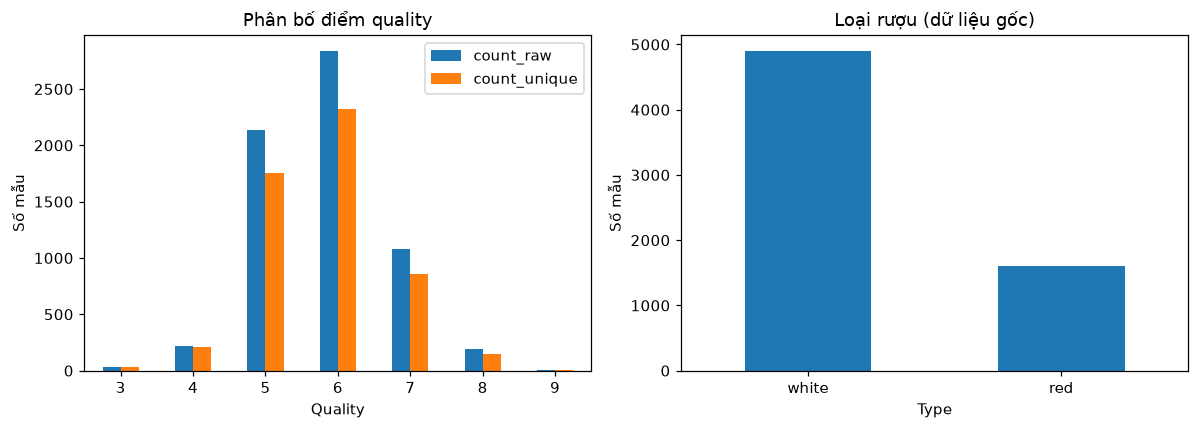

Sau loại trùng còn **5,320** mẫu. Quality 9 chỉ có **5** mẫu. Macro F1 cho mỗi lớp trọng số ngang nhau, cần báo cáo cùng support để không che giấu các lớp hiếm.

In [51]:
wine_raw = pd.read_csv("wine_quality_merged.csv")
wine_features = [c for c in wine_raw.columns if c != "quality"]
wine_numeric = [c for c in wine_features if c != "type"]
print("Kích thước gốc:", wine_raw.shape)
print("Thiếu dữ liệu:", int(wine_raw.isna().sum().sum()))
print("Dòng trùng hoàn toàn:", int(wine_raw.duplicated().sum()))
conflicting = wine_raw.groupby(wine_features, dropna=False).quality.nunique().gt(1).sum()
print("Nhóm cùng X nhưng khác quality:", int(conflicting))
assert wine_raw.isna().sum().sum() == 0, "Cần bổ sung imputer trong pipeline nếu nguồn có missing."
assert conflicting == 0, "Cần chia theo nhóm X nếu cùng đầu vào xuất hiện với nhiều nhãn."
assert set(wine_raw.type.unique()) == {"red", "white"}
wine = wine_raw.drop_duplicates().reset_index(drop=True)
wine["type"] = wine.type.map({"red": 0, "white": 1}).astype(int)
X_wine = wine[wine_numeric + ["type"]].copy()
y_wine = wine.quality.astype(int)
WINE_CLASSES = np.sort(y_wine.unique())
wine_distribution = pd.DataFrame({"count_raw": wine_raw.quality.value_counts(),
                                  "count_unique": y_wine.value_counts(),
                                  "percent_unique": 100*y_wine.value_counts(normalize=True)}).sort_index()
save_table(wine_distribution, "wine_phan_bo_lop")
display(wine_distribution.round(3))
display(wine[wine_numeric].describe().T.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
wine_distribution[["count_raw", "count_unique"]].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Phân bố điểm quality", xlabel="Quality", ylabel="Số mẫu")
wine_raw.type.value_counts().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Loại rượu (dữ liệu gốc)", xlabel="Type", ylabel="Số mẫu")
plt.tight_layout()
plt.show()
display(Markdown(f"Sau loại trùng còn **{len(wine):,}** mẫu. Quality 9 chỉ có **{int((y_wine==9).sum())}** mẫu. "
                 "Macro F1 cho mỗi lớp trọng số ngang nhau, cần báo cáo cùng support để không che giấu các lớp hiếm."))

## 12.2. Phân loại đa lớp quality
Chia stratified train/test 80/20. Chọn **Macro F1 CV** để coi các quality quan trọng ngang nhau.
Dùng **3 fold**, vì sau split train chỉ còn 4 mẫu quality 9; trong mỗi training fold chỉ có ít nhất 2 mẫu lớp này.
SMOTENC dùng `k_neighbors=1` để phù hợp với số mẫu hiếm thực tế. Với ít mẫu như vậy,
oversampling không tạo ra thông tin độc lập mới và kết quả quality 9 có độ bất định rất lớn.

Chuẩn hóa 11 feature số, giữ `type` ở dạng 0/1. Với mẫu hỗn hợp số và phân loại,
dùng **SMOTENC** để type sinh ra vẫn là category hợp lệ. ROS/RUS đa lớp mặc định cân bằng các lớp về lớp đông/ít nhất.
RUS toàn phần có thể chỉ còn vài chục mẫu, được giữ để minh họa hạn chế của cách này.
Thử Logistic Regression, KNN và Decision Tree với 4 chiến lược, cộng Dummy baseline.

,train,test
quality,,
3,24,6
4,165,41
5,1402,350
6,1858,465
7,685,171
8,118,30
9,4,1


Số mẫu lớp hiếm ít nhất trong training portion: 2


,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std,roc_auc_ovr_macro_mean,roc_auc_ovr_macro_std,ap_macro_mean,ap_macro_std
config,,,,,,,,,,,,,,,,
Decision Tree / ROS,0.4300,0.0204,0.3125,0.0681,0.2626,0.0321,0.3125,0.0681,0.2700,0.0454,0.4358,0.0315,0.6170,0.0415,0.2344,0.0386
KNN / No Sampling,0.5172,0.0084,0.2418,0.0058,0.2904,0.0306,0.2418,0.0058,0.2507,0.0107,0.5004,0.0070,0.6454,0.0307,0.2335,0.0155
KNN / SMOTENC,0.4180,0.0062,0.2911,0.0154,0.2432,0.0046,0.2911,0.0154,0.2461,0.0083,0.4358,0.0038,0.6281,0.0155,0.2208,0.0057
KNN / ROS,0.4243,0.0105,0.2673,0.0080,0.2362,0.0042,0.2673,0.0080,0.2404,0.0039,0.4358,0.0067,0.6071,0.0044,0.2120,0.0022
Logistic Regression / No Sampling,0.5463,0.0102,0.2320,0.0073,0.2952,0.0373,0.2320,0.0073,0.2346,0.0109,0.5165,0.0081,0.7859,0.0067,0.2934,0.0054
Decision Tree / No Sampling,0.4789,0.0100,0.2228,0.0165,0.2331,0.0220,0.2228,0.0165,0.2244,0.0182,0.4664,0.0079,0.6028,0.0059,0.2030,0.0023
Logistic Regression / ROS,0.3383,0.0183,0.3365,0.0568,0.2435,0.0033,0.3365,0.0568,0.2214,0.0072,0.3793,0.0150,0.7536,0.0008,0.2621,0.0051
Decision Tree / SMOTENC,0.3781,0.0182,0.2579,0.0080,0.2256,0.0069,0.2579,0.0080,0.2194,0.0025,0.4063,0.0198,0.6022,0.0077,0.2068,0.0098
Logistic Regression / SMOTENC,0.3289,0.0247,0.3190,0.0474,0.2433,0.0035,0.3190,0.0474,0.2166,0.0092,0.3750,0.0233,0.7389,0.0110,0.2570,0.0014


**Chọn bằng CV:** Decision Tree / ROS, Macro F1 = 0.2700 ± 0.0454. Test chưa tham gia lựa chọn.

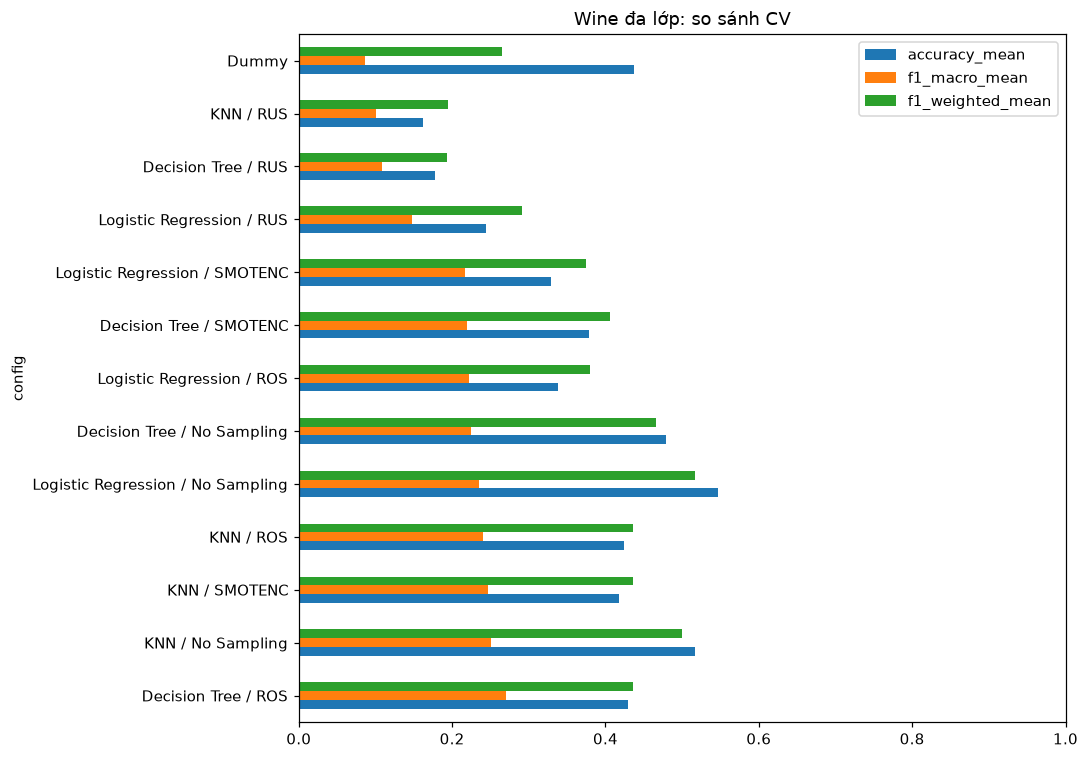

In [52]:
X_wtrain, X_wtest, y_wtrain, y_wtest = train_test_split(
    X_wine, y_wine, test_size=0.2, stratify=y_wine, random_state=RANDOM_STATE)
wine_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
split_distribution = pd.DataFrame({"train": y_wtrain.value_counts(), "test": y_wtest.value_counts()}).sort_index()
display(split_distribution)
save_table(split_distribution, "wine_multiclass_train_test")
assert set(X_wtrain.index).isdisjoint(X_wtest.index)
assert not X_wine.duplicated().any()
min_training_class = min(y_wtrain.iloc[tr].value_counts().min() for tr, _ in wine_cv.split(X_wtrain, y_wtrain))
print("Số mẫu lớp hiếm ít nhất trong training portion:", min_training_class)
assert min_training_class >= 2

def wine_preprocessor():
    return ColumnTransformer([("numeric", StandardScaler(), wine_numeric), ("type", "passthrough", ["type"])])

def wine_pipeline(classifier, sampler=None):
    steps = [("preprocess", wine_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("model", clone(classifier)))
    return ImbPipeline(steps)

def multiclass_ap(y_true, probability):
    return average_precision_score(label_binarize(y_true, classes=WINE_CLASSES), probability, average="macro")

wine_scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
    "f1_weighted": make_scorer(f1_score, average="weighted", zero_division=0),
    "roc_auc_ovr_macro": "roc_auc_ovr",
    "ap_macro": make_scorer(multiclass_ap, response_method="predict_proba"),
}
wine_samplers = {"No Sampling": None, "ROS": RandomOverSampler(random_state=RANDOM_STATE),
                 "RUS": RandomUnderSampler(random_state=RANDOM_STATE),
                 "SMOTENC": SMOTENC(categorical_features=[len(wine_numeric)], k_neighbors=1, random_state=RANDOM_STATE)}
wine_classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE),
}
wine_configs = {"Dummy": wine_pipeline(DummyClassifier(strategy="most_frequent"))}
for classifier_name, classifier in wine_classifiers.items():
    for sampler_name, sampler in wine_samplers.items():
        wine_configs[f"{classifier_name} / {sampler_name}"] = wine_pipeline(classifier, sampler)

wine_rows, wine_fold_rows = [], []
for name, pipeline in wine_configs.items():
    scores = cross_validate(pipeline, X_wtrain, y_wtrain, cv=wine_cv,
                            scoring=wine_scoring, error_score="raise", n_jobs=1)
    row = {"config": name}
    for metric in wine_scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    wine_rows.append(row)
    for fold in range(3):
        wine_fold_rows.append({"config": name, "fold": fold+1, **{m: scores[f"test_{m}"][fold] for m in wine_scoring}})
wine_results = pd.DataFrame(wine_rows).set_index("config").sort_values("f1_macro_mean", ascending=False)
save_table(wine_results, "wine_multiclass_cv")
save_table(pd.DataFrame(wine_fold_rows), "wine_multiclass_cv_tung_fold")
display(wine_results.round(4))
wine_best_name = wine_results.f1_macro_mean.idxmax()
wine_best_model = clone(wine_configs[wine_best_name])
display(Markdown(f"**Chọn bằng CV:** {wine_best_name}, Macro F1 = {wine_results.loc[wine_best_name, 'f1_macro_mean']:.4f} "
                 f"± {wine_results.loc[wine_best_name, 'f1_macro_std']:.4f}. Test chưa tham gia lựa chọn."))
wine_results[["accuracy_mean", "f1_macro_mean", "f1_weighted_mean"]].plot.barh(figsize=(10, 7), xlim=(0, 1))
plt.title("Wine đa lớp: so sánh CV")
plt.tight_layout()
plt.show()

## 12.3. Đánh giá cuối cùng trên test đa lớp
Fit cấu hình đã chọn trên toàn bộ train, đánh giá một lần. Không thay cấu hình sau khi xem test.
AP/ROC-AUC đa lớp dùng one-vs-rest rồi lấy macro; không so trực tiếp với AP của bài nhị phân.

Accuracy             0.3759
Balanced accuracy    0.2837
Precision macro      0.2389
Recall macro         0.2837
F1 macro             0.2303
F1 weighted          0.4078
ROC-AUC OVR macro    0.6102
AP macro             0.2252
Name: Wine multiclass test, dtype: float64

,precision,recall,f1-score,support
3,0.0000,0.0000,0.0000,6.0000
4,0.0928,0.4390,0.1532,41.0000
5,0.5482,0.4714,0.5069,350.0000
6,0.5302,0.3204,0.3995,465.0000
7,0.3595,0.3216,0.3395,171.0000
8,0.1413,0.4333,0.2131,30.0000
9,0.0000,0.0000,0.0000,1.0000
accuracy,0.3759,0.3759,0.3759,0.3759
macro avg,0.2389,0.2837,0.2303,1064.0000
weighted avg,0.4774,0.3759,0.4078,1064.0000


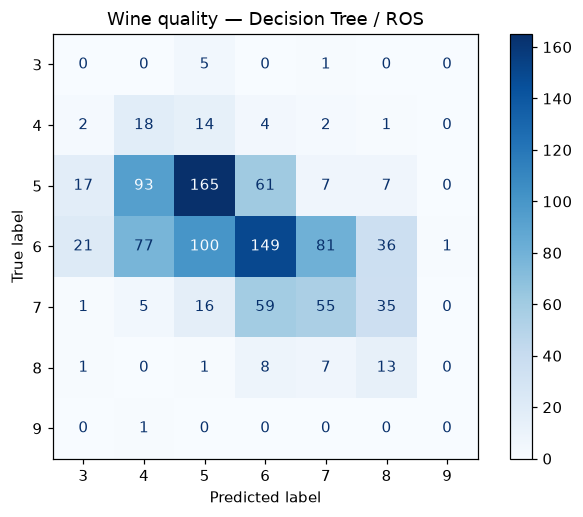

**Nhận xét test:** Accuracy 37.59%, Macro F1 0.2303, Weighted F1 0.4078. Cần xem riêng các lớp 3, 4, 8, 9 vì ít mẫu hơn nhiều so với 5, 6. Test chỉ có 1 mẫu quality 9 nên kết quả lớp này chưa đủ để kết luận khả năng tổng quát hóa.

In [53]:
wine_best_model.fit(X_wtrain, y_wtrain)
wine_pred = wine_best_model.predict(X_wtest)
wine_prob = wine_best_model.predict_proba(X_wtest)
assert np.array_equal(wine_best_model.classes_, WINE_CLASSES)
wine_test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_wtest, wine_pred),
    "Balanced accuracy": balanced_accuracy_score(y_wtest, wine_pred),
    "Precision macro": precision_score(y_wtest, wine_pred, average="macro", zero_division=0),
    "Recall macro": recall_score(y_wtest, wine_pred, average="macro", zero_division=0),
    "F1 macro": f1_score(y_wtest, wine_pred, average="macro", zero_division=0),
    "F1 weighted": f1_score(y_wtest, wine_pred, average="weighted", zero_division=0),
    "ROC-AUC OVR macro": roc_auc_score(y_wtest, wine_prob, multi_class="ovr", average="macro", labels=WINE_CLASSES),
    "AP macro": multiclass_ap(y_wtest, wine_prob),
}, name="Wine multiclass test")
save_table(wine_test_metrics, "wine_multiclass_test_metrics")
wine_report = pd.DataFrame(classification_report(y_wtest, wine_pred, labels=WINE_CLASSES, output_dict=True, zero_division=0)).T
save_table(wine_report, "wine_multiclass_classification_report")
wine_predictions = pd.DataFrame({"quality_true": y_wtest, "quality_pred": wine_pred})
for j, cls in enumerate(WINE_CLASSES):
    wine_predictions[f"p_quality_{cls}"] = wine_prob[:, j]
save_table(wine_predictions, "wine_multiclass_test_du_doan")
display(wine_test_metrics.round(4))
display(wine_report.round(4))
ConfusionMatrixDisplay.from_predictions(y_wtest, wine_pred, labels=WINE_CLASSES, cmap="Blues")
plt.title(f"Wine quality — {wine_best_name}")
plt.tight_layout()
plt.show()
display(Markdown(f"**Nhận xét test:** Accuracy {wine_test_metrics['Accuracy']:.2%}, Macro F1 {wine_test_metrics['F1 macro']:.4f}, "
                 f"Weighted F1 {wine_test_metrics['F1 weighted']:.4f}. "
                 "Cần xem riêng các lớp 3, 4, 8, 9 vì ít mẫu hơn nhiều so với 5, 6. "
                 f"Test chỉ có {int((y_wtest==9).sum())} mẫu quality 9 nên kết quả lớp này chưa đủ để kết luận khả năng tổng quát hóa."))

## 12.4. Bổ sung: Wine nhị phân, good = quality ≥ 7
Quy ước ngưỡng được đặt trước thí nghiệm. Chia stratified 80/20 riêng cho nhãn nhị phân,
dùng 5-fold CV trên train, Logistic Regression và 4 chiến lược sampling.
SMOTENC có thể dùng `k_neighbors=5` vì minority nhị phân đủ mẫu.
Chọn theo F1 CV, sau đó đánh giá test một lần, ngưỡng dự đoán mặc định 0.5.

,all,train,test
quality,,,
0,4311,3449,862
1,1009,807,202


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
config,,,,,,,,,,,,
RUS,0.7394,0.0128,0.4043,0.0161,0.7893,0.0372,0.5346,0.0207,0.8287,0.0138,0.5184,0.0236
SMOTENC,0.7439,0.0155,0.4080,0.0183,0.7720,0.0387,0.5335,0.0190,0.8304,0.0151,0.5217,0.0243
ROS,0.7399,0.0170,0.4043,0.0204,0.7794,0.0393,0.5321,0.0221,0.8303,0.0144,0.5228,0.0249
No Sampling,0.8280,0.0074,0.5926,0.0489,0.3086,0.0213,0.4047,0.0183,0.8316,0.0146,0.5263,0.0242
Dummy,0.8104,0.0006,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.1896,0.0006


Accuracy     0.7237
Precision    0.3883
Recall       0.7921
F1           0.5212
ROC-AUC      0.8162
AP           0.4796
Name: Wine binary test, dtype: float64

              precision    recall  f1-score   support

 quality < 7     0.9356    0.7077    0.8058       862
quality >= 7     0.3883    0.7921    0.5212       202

    accuracy                         0.7237      1064
   macro avg     0.6620    0.7499    0.6635      1064
weighted avg     0.8317    0.7237    0.7518      1064



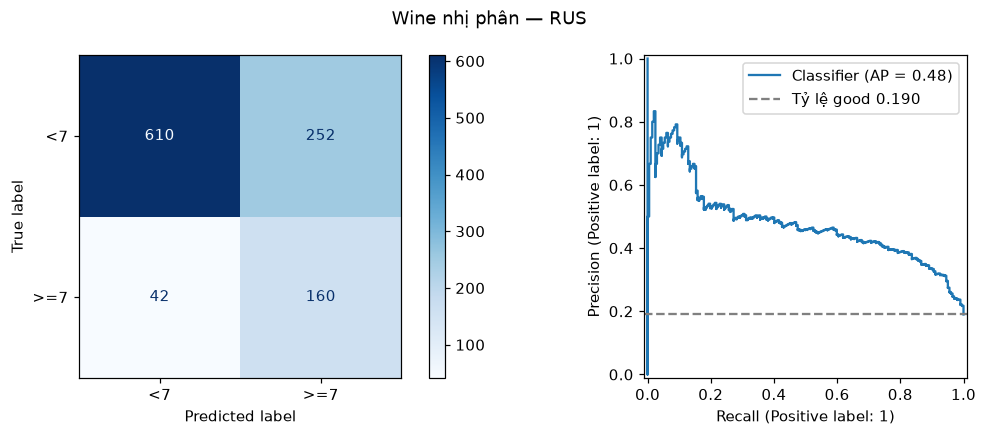

**Chọn theo CV:** RUS. Test Precision 0.3883, Recall 0.7921, F1 0.5212, AP 0.4796 (tỷ lệ good 0.1898). TN=610, FP=252, FN=42, TP=160. Sampling có thể tăng số mẫu good phát hiện được nhưng cũng tăng cảnh báo sai. Xác suất sau sampling chưa được hiệu chỉnh theo tỷ lệ lớp thực tế, nên không diễn giải trực tiếp như xác suất chất lượng đã được calibration.

In [54]:
y_good = (y_wine >= 7).astype(int)
X_gtrain, X_gtest, y_gtrain, y_gtest = train_test_split(
    X_wine, y_good, test_size=0.2, stratify=y_good, random_state=RANDOM_STATE)
display(pd.DataFrame({"all": y_good.value_counts(), "train": y_gtrain.value_counts(), "test": y_gtest.value_counts()}).sort_index())
good_samplers = dict(wine_samplers)
good_samplers["SMOTENC"] = SMOTENC(categorical_features=[len(wine_numeric)], k_neighbors=5, random_state=RANDOM_STATE)
good_configs = {name: wine_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), sampler)
                for name, sampler in good_samplers.items()}
good_configs["Dummy"] = wine_pipeline(DummyClassifier(strategy="most_frequent"))
good_results = compare_configs(good_configs, X_gtrain, y_gtrain, skf).sort_values("f1_mean", ascending=False)
save_table(good_results, "wine_binary_cv")
display(good_results.round(4))
good_best_name = good_results.f1_mean.idxmax()
good_best_model = clone(good_configs[good_best_name]).fit(X_gtrain, y_gtrain)
good_pred = good_best_model.predict(X_gtest)
good_prob = good_best_model.predict_proba(X_gtest)[:, 1]
good_test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_gtest, good_pred),
    "Precision": precision_score(y_gtest, good_pred, zero_division=0),
    "Recall": recall_score(y_gtest, good_pred, zero_division=0),
    "F1": f1_score(y_gtest, good_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_gtest, good_prob),
    "AP": average_precision_score(y_gtest, good_prob),
}, name="Wine binary test")
save_table(good_test_metrics, "wine_binary_test_metrics")
save_table(pd.DataFrame({"good_true": y_gtest, "good_pred": good_pred, "p_good": good_prob}), "wine_binary_test_du_doan")
display(good_test_metrics.round(4))
print(classification_report(y_gtest, good_pred, target_names=["quality < 7", "quality >= 7"], digits=4, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_gtest, good_pred, display_labels=["<7", ">=7"], ax=axes[0], cmap="Blues")
PrecisionRecallDisplay.from_predictions(y_gtest, good_prob, ax=axes[1])
axes[1].axhline(y_gtest.mean(), linestyle="--", color="gray", label=f"Tỷ lệ good {y_gtest.mean():.3f}")
axes[1].legend()
fig.suptitle(f"Wine nhị phân — {good_best_name}")
plt.tight_layout()
plt.show()
gtn, gfp, gfn, gtp = confusion_matrix(y_gtest, good_pred, labels=[0, 1]).ravel()
display(Markdown(f"**Chọn theo CV:** {good_best_name}. Test Precision {good_test_metrics['Precision']:.4f}, "
                 f"Recall {good_test_metrics['Recall']:.4f}, F1 {good_test_metrics['F1']:.4f}, AP {good_test_metrics['AP']:.4f} "
                 f"(tỷ lệ good {y_gtest.mean():.4f}). TN={gtn}, FP={gfp}, FN={gfn}, TP={gtp}. "
                 "Sampling có thể tăng số mẫu good phát hiện được nhưng cũng tăng cảnh báo sai. "
                 "Xác suất sau sampling chưa được hiệu chỉnh theo tỷ lệ lớp thực tế, nên không diễn giải trực tiếp như xác suất chất lượng đã được calibration."))

## 12.5. Kết luận và giới hạn
- Breast Cancer: Accuracy của Dummy cao nhưng Recall malignant bằng 0; lựa chọn cần thêm F1, Recall và AP.
- Scaler và sampler luôn nằm trong pipeline khi CV; validation/test không được resample.
- Wine: đã loại trùng, xử lý type như feature phân loại, so sánh baseline và sampling,
  lựa chọn qua CV trước khi đánh giá test. Phân loại trực tiếp quality khó hơn bài nhị phân vì phải phân biệt nhiều mức gần nhau.
- CV một seed và test nhỏ ở các lớp hiếm chưa đủ cho khẳng định chắc chắn. Chọn nhiều cấu hình trên cùng CV còn có thể làm
  điểm CV của cấu hình thắng lạc quan; test độc lập là kiểm tra cuối, không dùng để tiếp tục tuning.
- Nếu cần cải thiện tiếp: thu thập thêm quality hiếm, repeated/nested CV, tuning trong train và calibration với dữ liệu riêng.
  Khi đã dùng test hiện tại để báo cáo, các quyết định mới cần được kiểm chứng bằng một tập holdout mới.

**Tài liệu đối chiếu:** notebook gốc và slide 25 trong `tai_lieu_goc/`.
Các bảng chi tiết, dự đoán test và phiên bản môi trường được lưu trong `ket_qua/`.

In [55]:
summary = {
    "breast_cancer": {"selected": best_name, "test": test_metrics.to_dict()},
    "wine_multiclass": {"selected": wine_best_name, "cv_macro_f1": float(wine_results.loc[wine_best_name, "f1_macro_mean"]), "test": wine_test_metrics.to_dict()},
    "wine_binary": {"selected": good_best_name, "test": good_test_metrics.to_dict()},
    "wine_raw_rows": len(wine_raw), "wine_unique_rows": len(wine),
    "seed": RANDOM_STATE,
}
(OUTPUT / "tom_tat.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Hoàn tất: ví dụ gốc, 7 bài tập và Wine Quality (đa lớp + nhị phân).")
print("Số bảng CSV đã lưu:", len(list(OUTPUT.glob("*.csv"))))

Hoàn tất: ví dụ gốc, 7 bài tập và Wine Quality (đa lớp + nhị phân).
Số bảng CSV đã lưu: 21


## Tài liệu kỹ thuật đối chiếu

- [imbalanced-learn: tránh data leakage khi resampling](https://imbalanced-learn.org/stable/common_pitfalls.html).
- [imbalanced-learn: SMOTENC cho dữ liệu số và phân loại](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html).
- [scikit-learn: định nghĩa Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).


## Nhận định từ kết quả Wine thực tế

Ở bài đa lớp, mô hình thắng theo Macro F1 CV là Decision Tree + ROS. Test đạt Macro F1 khoảng **0,2303**
và Accuracy **37,59%**. Đây là hiệu năng còn thấp; việc thắng trong nhóm cấu hình đã thử không đồng nghĩa
mô hình tốt. Macro F1 ưu tiên các lớp hiếm khiến lựa chọn có thể đánh đổi Accuracy của các lớp đông mẫu.
Không thể khẳng định mô hình nhận diện tốt tất cả mức quality, đặc biệt quality 9 có đúng một mẫu test.

Ở bài nhị phân, RUS thắng theo F1 CV nhưng chỉ hơn SMOTENC khoảng **0,0011**, nhỏ so với std khoảng **0,02**.
Test RUS đạt F1 **0,5212**, Recall **79,21%** và Precision **38,83%**. Như vậy mô hình phát hiện được nhiều wine good
nhưng phần lớn dự đoán good vẫn sai. AP **0,4796** cao hơn tỷ lệ good test khoảng **18,98%**,
song chất lượng phân loại còn hạn chế. Các kết quả được giữ nguyên để báo cáo trung thực, không điều chỉnh mô hình theo test.


# PHẦN 13. KIỂM TRA THEO CÁC Ý TRONG ẢNH

## 13.1. Chỗ đã có và chỗ cần bổ sung

| Ý cần chuẩn bị | Bản trước | Bản rà soát |
| --- | --- | --- |
| Nguyên lý thuật toán, cách chương trình chạy | Có mã, giải thích mô hình còn ít | Thêm giải thích và ví dụ đi qua pipeline |
| So sánh K=5/K=7 | Chỉ có K=3/5/10 theo đề gốc | Thêm K=7, so cả KFold và StratifiedKFold |
| Căn cứ xét chỉ số, mô hình tối ưu hơn | Chọn F1/Macro F1, chưa đối chiếu mục tiêu Accuracy | Báo cáo hai lựa chọn bằng cùng CV, giữ tiêu chí chính là Macro F1 |
| Thử thêm model để cải thiện | Wine có LR/KNN/Tree | Thêm Random Forest, Extra Trees, Histogram Gradient Boosting và tuning |
| Quality dựa vào gì | Có cột quality và ngưỡng tự quy ước | Giải thích nguồn nhãn, feature và ngưỡng rõ ràng |

Đây là đối chiếu với thông tin trong ảnh, không khẳng định ảnh là rubric chính thức của giảng viên.
Ảnh không chỉ rõ “hai cách” là gì, nên bổ sung cả so sánh **KFold/StratifiedKFold**
và so sánh **chọn theo Accuracy/Macro F1**.

## 13.2. Quality là nhãn gì?
Theo [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), đầu vào là các phép đo hóa lý,
còn đầu ra quality là **điểm đánh giá cảm quan**, trên thang 0–10.
File đang làm chỉ có các điểm 3–9. Điểm đã được ghi trong dataset, không do chương trình tính bằng công thức alcohol/pH.
Mô hình học quan hệ từ dữ liệu đã có nhãn để dự đoán quality của mẫu mới bằng 11 feature hóa lý và type.

Với bài đa lớp, giữ nguyên quality. Với bài nhị phân bổ sung, quy ước `quality >= 7` là good.
Ngưỡng này do người làm đặt để định nghĩa bài toán, không phải ngưỡng do UCI/đề bài quy định.
Đổi ngưỡng làm đổi nhãn, tỷ lệ lớp và độ khó, nên không so trực tiếp Accuracy giữa hai bài toán.

## 13.3. K=5 so với K=7; KFold so với StratifiedKFold
Hiểu “5K/7K” trong ảnh là số fold, ký hiệu chuẩn là K=5/K=7.
Nếu nói KNN, chữ k lại là số láng giềng, đây là hai tham số khác nhau.

Cùng Logistic Regression, StandardScaler, không sampling và seed 42, thực hiện trên Breast Cancer
và Wine nhị phân. Đây là thí nghiệm về cách đánh giá, không dùng để chọn cấu hình trên test.

Không áp dụng 5/7-fold có đủ mọi lớp cho wine 7 lớp: train chỉ có 4 mẫu quality 9,
nên K lớn hơn 4 không thể để mỗi validation fold có lớp này. Phần wine đa lớp giữ 3-fold.

In [56]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
import time

review_rows, review_fold_rows = [], []
datasets_review = {
    "Breast Cancer": (X_train, y_train, make_binary_pipeline()),
    "Wine binary": (X_gtrain, y_gtrain, wine_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))),
}
for dataset_name, (xx, yy, pipeline) in datasets_review.items():
    for k in [5, 7]:
        for splitter_name, splitter_class in [("KFold", KFold), ("StratifiedKFold", StratifiedKFold)]:
            splitter = splitter_class(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
            row = cv_summary(clone(pipeline), xx, yy, splitter)
            dist = get_fold_distribution(splitter, xx.reset_index(drop=True), yy.reset_index(drop=True), splitter_name)
            dist = dist.rename(columns={"Train malignant (%)": "train_positive_percent", "Validation malignant (%)": "validation_positive_percent"})
            dist["dataset"], dist["K"] = dataset_name, k
            review_fold_rows.append(dist)
            review_rows.append({"dataset": dataset_name, "splitter": splitter_name, "K": k,
                                "positive_min_percent": dist.validation_positive_percent.min(),
                                "positive_max_percent": dist.validation_positive_percent.max(), **row})
review_folds = pd.DataFrame(review_rows)
save_table(review_folds, "ra_soat_k5_k7")
save_table(pd.concat(review_fold_rows, ignore_index=True), "ra_soat_k5_k7_phan_bo_fold")
display(review_folds[["dataset", "splitter", "K", "positive_min_percent", "positive_max_percent",
                      "accuracy_mean", "accuracy_std", "recall_mean", "recall_std", "f1_mean", "f1_std", "pr_auc_mean"]].round(4))
display(Markdown("**Cách kết luận:** K=7 dùng 6/7 train để fit mỗi lần, K=5 dùng 4/5; K=7 tốn nhiều lượt fit hơn "
                 "và validation nhỏ hơn. So đồng thời mean, std, số mẫu dương và chi phí; không mặc định K=7 tốt hơn. "
                 "Stratification giữ tỷ lệ lớp gần nhau nhưng không bảo đảm std của mọi metric thấp hơn trong mọi lần chia."))

,dataset,splitter,K,positive_min_percent,positive_max_percent,accuracy_mean,accuracy_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean
0,Breast Cancer,KFold,5,10.4478,17.9104,0.9880,0.0125,0.9012,0.1177,0.9446,0.0685,0.9891
1,Breast Cancer,StratifiedKFold,5,13.6364,14.9254,0.9850,0.0183,0.9400,0.1342,0.9447,0.0722,0.9855
2,Breast Cancer,KFold,7,8.3333,18.7500,0.9909,0.0113,0.9556,0.0801,0.9673,0.0443,0.9857
3,Breast Cancer,StratifiedKFold,7,12.7660,14.8936,0.9880,0.0164,0.9388,0.1124,0.9542,0.0645,0.9885
4,Wine binary,KFold,5,17.9788,21.9741,0.8282,0.0129,0.3120,0.0493,0.4060,0.0517,0.5211
5,Wine binary,StratifiedKFold,5,18.9189,19.0364,0.8280,0.0074,0.3086,0.0213,0.4047,0.0183,0.5263
6,Wine binary,KFold,7,16.9408,22.6974,0.8268,0.0177,0.3108,0.0524,0.4032,0.0605,0.5274
7,Wine binary,StratifiedKFold,7,18.9145,19.0789,0.8268,0.0143,0.3110,0.0226,0.4057,0.0341,0.5292


**Cách kết luận:** K=7 dùng 6/7 train để fit mỗi lần, K=5 dùng 4/5; K=7 tốn nhiều lượt fit hơn và validation nhỏ hơn. So đồng thời mean, std, số mẫu dương và chi phí; không mặc định K=7 tốt hơn. Stratification giữ tỷ lệ lớp gần nhau nhưng không bảo đảm std của mọi metric thấp hơn trong mọi lần chia.

# PHẦN 14. THÊM MÔ HÌNH VÀ TUNING CHO WINE ĐA LỚP

## 14.1. Mục tiêu và kỷ luật đánh giá
Giữ nguyên X, y, dữ liệu đã loại trùng, train/test và 3 fold của Phần 12 để đối chiếu cùng bài toán.
Tiêu chí **chính vẫn là Macro F1**, thêm lựa chọn theo Accuracy để giải thích mục tiêu khác nhau dẫn đến lựa chọn khác nhau.
Không đổi nhãn/seed và không lặp tuning để cố đạt 64%.

Tất cả tuning dưới đây chỉ dùng train. Tuy nhiên test này đã được xem ở bản trước:
điểm test mới là **đối chiếu trên test đã dùng**, không phải xác nhận độc lập cho vòng cải tiến.
Cần dữ liệu chưa từng dùng hoặc thiết kế đánh giá lồng nhau cho nghiên cứu tiếp theo.

## 14.2. Vì sao thử các mô hình này?
- **Random Forest:** huấn luyện nhiều cây trên các mẫu bootstrap và tập feature ngẫu nhiên tại các nút,
  rồi trung bình xác suất lớp. Thường giảm phương sai của một cây, học quan hệ phi tuyến và tương tác.
- **Extra Trees:** cũng gộp nhiều cây, thêm ngẫu nhiên ở ngưỡng chia; mặc định không bootstrap.
  Ngẫu nhiên hóa mạnh giúp đa dạng cây, nhưng không bảo đảm thắng Random Forest.
- **Histogram Gradient Boosting:** bổ sung cây theo từng vòng để giảm loss còn lại, dùng histogram để xét ngưỡng.
  Với nhiều lớp, mỗi vòng có cây cho từng lớp. Learning rate và độ phức tạp cây kiểm soát mức học.

Không cần scale cho bản thân các cây, nhưng giữ preprocessor trong pipeline để nhất quán thứ tự cột.
Type có hai giá trị nên mã 0/1 hợp lệ cho các phép tách cây ở đây.
Thử `class_weight` trên forest thay vì mặc định cân bằng toàn phần các lớp cực hiếm.
Class weighting vẫn không tạo thêm dữ liệu thực cho quality 9.

Nguồn: [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[Extra Trees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html),
[HistGradientBoosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).

## 14.3. Không gian tìm kiếm đặt trước
Mỗi họ 4 cấu hình, mỗi cấu hình 3 fold, tổng 36 lượt fit cho tìm kiếm, cộng refit cấu hình tốt nhất mỗi họ.
Forest thay min_samples_leaf (1/2) và class_weight (không/cân bằng).
Boosting thay max_leaf_nodes (15/31) và L2 (0/1); giữ 200 vòng, learning rate 0.08, tắt early stopping để không cần chia thêm lớp hiếm.
Lưu từng tham số và điểm từng fold. Không gian nhỏ này phục vụ bài thực hành, chưa phải tối ưu toàn diện.

In [57]:
search_specs = {
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, max_features="sqrt", n_jobs=2, random_state=RANDOM_STATE),
        {"model__min_samples_leaf": [1, 2], "model__class_weight": [None, "balanced_subsample"]}),
    "Extra Trees": (
        ExtraTreesClassifier(n_estimators=400, max_features=1.0, n_jobs=2, random_state=RANDOM_STATE),
        {"model__min_samples_leaf": [1, 2], "model__class_weight": [None, "balanced"]}),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, min_samples_leaf=15,
                                       early_stopping=False, categorical_features=[len(wine_numeric)], random_state=RANDOM_STATE),
        {"model__max_leaf_nodes": [15, 31], "model__l2_regularization": [0.0, 1.0]}),
}
searches = {}
extended_configs = {name: clone(model) for name, model in wine_configs.items()}
extended_rows, extended_fold_rows = [], []

def run_model_search(family):
    estimator, grid = search_specs[family]
    search = GridSearchCV(wine_pipeline(estimator), grid, scoring=wine_scoring,
                          refit="f1_macro", cv=wine_cv, n_jobs=1, error_score="raise", return_train_score=False)
    start = time.perf_counter()
    search.fit(X_wtrain, y_wtrain)
    elapsed = time.perf_counter() - start
    searches[family] = search
    records = []
    for i, params in enumerate(search.cv_results_["params"]):
        name = f"{family} / grid{i+1:02d}"
        row = {"config": name, "family": family, "params": json.dumps(params, ensure_ascii=False),
               "mean_fit_time": float(search.cv_results_["mean_fit_time"][i])}
        extended_configs[name] = clone(search.estimator).set_params(**params)
        for metric in wine_scoring:
            values = np.array([search.cv_results_[f"split{j}_test_{metric}"][i] for j in range(3)])
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        extended_rows.append(row)
        records.append(row)
        for fold in range(3):
            extended_fold_rows.append({"config": name, "fold": fold+1,
                **{m: float(search.cv_results_[f"split{fold}_test_{m}"][i]) for m in wine_scoring}})
    table = pd.DataFrame(records).set_index("config")
    save_table(table, f"ra_soat_search_{family.replace(' ', '_')}")
    print(f"{family}: {len(records)} cấu hình; thời gian {elapsed:.1f}s; best params = {search.best_params_}")
    display(table[["params", "accuracy_mean", "f1_macro_mean", "f1_macro_std", "f1_weighted_mean", "ap_macro_mean"]].round(4))

In [58]:
run_model_search("Random Forest")

Random Forest: 4 cấu hình; thời gian 14.3s; best params = {'model__class_weight': 'balanced_subsample', 'model__min_samples_leaf': 2}


,params,accuracy_mean,f1_macro_mean,f1_macro_std,f1_weighted_mean,ap_macro_mean
config,,,,,,
Random Forest / grid01,"{""model__class_weight"": null, ""model__min_samp...",0.5710,0.2544,0.0027,0.5457,0.3017
Random Forest / grid02,"{""model__class_weight"": null, ""model__min_samp...",0.5710,0.2399,0.0011,0.5416,0.3062
Random Forest / grid03,"{""model__class_weight"": ""balanced_subsample"", ...",0.5742,0.2489,0.0087,0.5454,0.3140
Random Forest / grid04,"{""model__class_weight"": ""balanced_subsample"", ...",0.5698,0.2664,0.0047,0.5513,0.3173


In [59]:
run_model_search("Extra Trees")

Extra Trees: 4 cấu hình; thời gian 21.6s; best params = {'model__class_weight': 'balanced', 'model__min_samples_leaf': 2}


,params,accuracy_mean,f1_macro_mean,f1_macro_std,f1_weighted_mean,ap_macro_mean
config,,,,,,
Extra Trees / grid01,"{""model__class_weight"": null, ""model__min_samp...",0.5536,0.2654,0.0056,0.5349,0.3021
Extra Trees / grid02,"{""model__class_weight"": null, ""model__min_samp...",0.5670,0.2575,0.0091,0.5437,0.3026
Extra Trees / grid03,"{""model__class_weight"": ""balanced"", ""model__mi...",0.5620,0.2709,0.0188,0.5415,0.3088
Extra Trees / grid04,"{""model__class_weight"": ""balanced"", ""model__mi...",0.5576,0.2973,0.0177,0.5474,0.3111


In [60]:
run_model_search("HistGradientBoosting")

HistGradientBoosting: 4 cấu hình; thời gian 19.9s; best params = {'model__l2_regularization': 1.0, 'model__max_leaf_nodes': 15}


,params,accuracy_mean,f1_macro_mean,f1_macro_std,f1_weighted_mean,ap_macro_mean
config,,,,,,
HistGradientBoosting / grid01,"{""model__l2_regularization"": 0.0, ""model__max_...",0.5489,0.2489,0.0045,0.5288,0.2815
HistGradientBoosting / grid02,"{""model__l2_regularization"": 0.0, ""model__max_...",0.5461,0.2522,0.0063,0.5269,0.2873
HistGradientBoosting / grid03,"{""model__l2_regularization"": 1.0, ""model__max_...",0.5522,0.2586,0.0026,0.5335,0.3169
HistGradientBoosting / grid04,"{""model__l2_regularization"": 1.0, ""model__max_...",0.5486,0.2540,0.0052,0.5298,0.3244


## 14.4. Chọn theo hai tiêu chí trên cùng bảng CV
Gộp 13 baseline và 12 cấu hình mới. Xếp hạng chính theo Macro F1; nếu hòa thì dùng Accuracy rồi tên cấu hình
để kết quả tái lập. Xếp hạng phụ theo Accuracy để phục vụ câu hỏi “tối ưu hơn theo chỉ số nào”.
**Chốt cả hai cấu hình bằng CV trước khi tính test**, không chọn lại theo test.

,accuracy_mean,accuracy_std,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std,f1_weighted_mean,ap_macro_mean
config,,,,,,,,
Extra Trees / grid04,0.5576,0.0120,0.3406,0.2838,0.2973,0.0177,0.5474,0.3111
Extra Trees / grid03,0.5620,0.0052,0.3398,0.2580,0.2709,0.0188,0.5415,0.3088
Decision Tree / ROS,0.4300,0.0204,0.2626,0.3125,0.2700,0.0454,0.4358,0.2344
Random Forest / grid04,0.5698,0.0089,0.3190,0.2597,0.2664,0.0047,0.5513,0.3173
Extra Trees / grid01,0.5536,0.0073,0.3276,0.2537,0.2654,0.0056,0.5349,0.3021
HistGradientBoosting / grid03,0.5522,0.0071,0.3277,0.2505,0.2586,0.0026,0.5335,0.3169
Extra Trees / grid02,0.5670,0.0052,0.3413,0.2500,0.2575,0.0091,0.5437,0.3026
Random Forest / grid01,0.5710,0.0056,0.3517,0.2480,0.2544,0.0027,0.5457,0.3017
HistGradientBoosting / grid04,0.5486,0.0071,0.3000,0.2475,0.2540,0.0052,0.5298,0.3244


,criterion,config,cv_accuracy,cv_macro_f1,cv_macro_f1_std
0,Macro F1 (chính),Extra Trees / grid04,0.5576,0.2973,0.0177
1,Accuracy (đối chiếu),Random Forest / grid03,0.5742,0.2489,0.0087


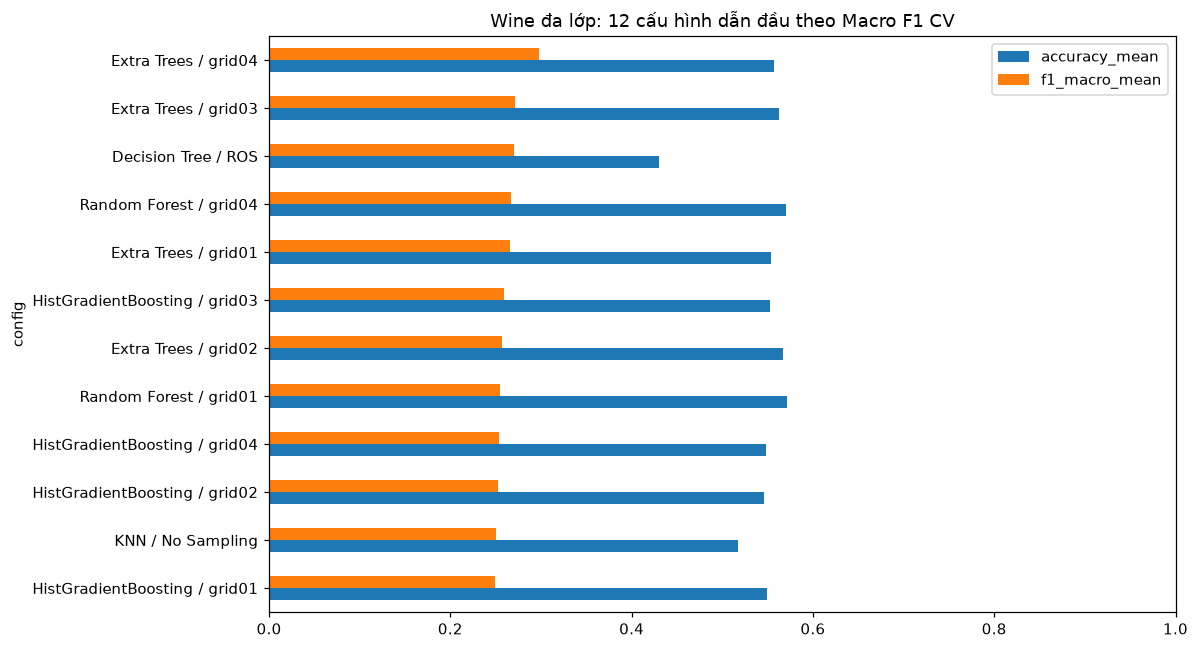

In [61]:
new_results = pd.DataFrame(extended_rows).set_index("config")
full_results = pd.concat([wine_results, new_results], axis=0)
full_results.index.name = "config"
full_results = full_results.reset_index().sort_values(["f1_macro_mean", "accuracy_mean", "config"], ascending=[False, False, True]).set_index("config")
accuracy_ranking = full_results.reset_index().sort_values(["accuracy_mean", "f1_macro_mean", "config"], ascending=[False, False, True]).set_index("config")
selected_by_cv = {"Macro F1 (chính)": full_results.index[0], "Accuracy (đối chiếu)": accuracy_ranking.index[0]}
save_table(full_results, "ra_soat_wine_multiclass_cv")
save_table(pd.DataFrame(extended_fold_rows), "ra_soat_wine_multiclass_cv_tung_fold_moi")
selection_table = pd.DataFrame([
    {"criterion": criterion, "config": name, "cv_accuracy": full_results.loc[name, "accuracy_mean"],
     "cv_macro_f1": full_results.loc[name, "f1_macro_mean"], "cv_macro_f1_std": full_results.loc[name, "f1_macro_std"]}
    for criterion, name in selected_by_cv.items()])
save_table(selection_table, "ra_soat_chot_lua_chon_truoc_test")
display(full_results[["accuracy_mean", "accuracy_std", "precision_macro_mean", "recall_macro_mean", "f1_macro_mean", "f1_macro_std", "f1_weighted_mean", "ap_macro_mean"]].round(4))
display(selection_table.round(4))
full_results.head(12)[["accuracy_mean", "f1_macro_mean"]].iloc[::-1].plot.barh(figsize=(11, 6), xlim=(0, 1))
plt.title("Wine đa lớp: 12 cấu hình dẫn đầu theo Macro F1 CV")
plt.tight_layout()
plt.show()

,precision,recall,f1-score,support
3,0.0000,0.0000,0.0000,6.0000
4,0.3333,0.2439,0.2817,41.0000
5,0.5985,0.6771,0.6354,350.0000
6,0.5591,0.5591,0.5591,465.0000
7,0.4601,0.4386,0.4491,171.0000
8,0.4000,0.1333,0.2000,30.0000
9,0.0000,0.0000,0.0000,1.0000
accuracy,0.5508,0.5508,0.5508,0.5508
macro avg,0.3359,0.2932,0.3036,1064.0000
weighted avg,0.5393,0.5508,0.5420,1064.0000


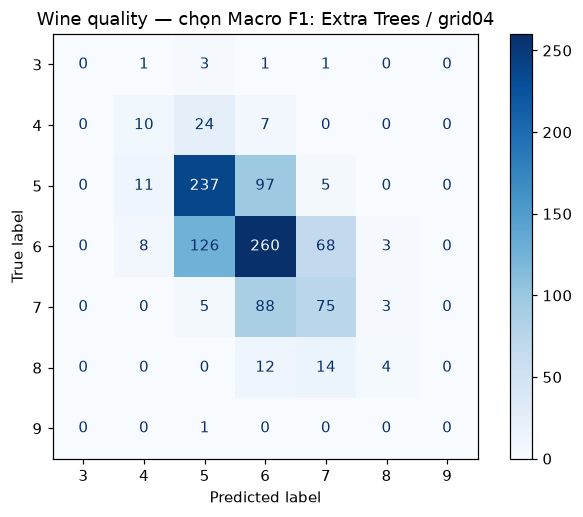

,config,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted,ROC-AUC OVR macro,AP macro
criterion,,,,,,,,
Macro F1 (chính),Extra Trees / grid04,0.5508,0.3359,0.2932,0.3036,0.5420,0.7489,0.3271
Accuracy (đối chiếu),Random Forest / grid03,0.5648,0.4414,0.2494,0.2604,0.5387,0.7505,0.3333


**Lựa chọn chính:** Extra Trees / grid04. Trên test đã dùng: Accuracy **55.08%**, Macro F1 **0.3036**; baseline cũ Accuracy 37.59%, Macro F1 0.2303. Đây là đối chiếu cùng nhãn/split, không phải xác nhận trên dữ liệu mới. Mô hình được chọn theo CV, không chọn theo bảng test. Test quality 9 chỉ có một mẫu nên không kết luận chắc chắn về lớp này.

In [62]:
review_test_rows, reviewed_fitted = [], {}
for criterion, name in selected_by_cv.items():
    if name not in reviewed_fitted:
        reviewed_fitted[name] = clone(extended_configs[name]).fit(X_wtrain, y_wtrain)
    model = reviewed_fitted[name]
    prediction = model.predict(X_wtest)
    probability = model.predict_proba(X_wtest)
    assert np.array_equal(model.classes_, WINE_CLASSES)
    row = {"criterion": criterion, "config": name,
           "Accuracy": accuracy_score(y_wtest, prediction),
           "Precision macro": precision_score(y_wtest, prediction, average="macro", zero_division=0),
           "Recall macro": recall_score(y_wtest, prediction, average="macro", zero_division=0),
           "F1 macro": f1_score(y_wtest, prediction, average="macro", zero_division=0),
           "F1 weighted": f1_score(y_wtest, prediction, average="weighted", zero_division=0),
           "ROC-AUC OVR macro": roc_auc_score(y_wtest, probability, multi_class="ovr", average="macro", labels=WINE_CLASSES),
           "AP macro": multiclass_ap(y_wtest, probability)}
    review_test_rows.append(row)
    suffix = "macro_f1" if criterion.startswith("Macro") else "accuracy"
    predictions = pd.DataFrame({"quality_true": y_wtest, "quality_pred": prediction})
    for j, cls in enumerate(WINE_CLASSES):
        predictions[f"p_quality_{cls}"] = probability[:, j]
    save_table(predictions, f"ra_soat_wine_multiclass_test_{suffix}_du_doan")
    per_class = pd.DataFrame(classification_report(y_wtest, prediction, labels=WINE_CLASSES, output_dict=True, zero_division=0)).T
    save_table(per_class, f"ra_soat_wine_multiclass_report_{suffix}")
    if criterion.startswith("Macro"):
        display(per_class.round(4))
        ConfusionMatrixDisplay.from_predictions(y_wtest, prediction, labels=WINE_CLASSES, cmap="Blues")
        plt.title(f"Wine quality — chọn Macro F1: {name}")
        plt.tight_layout()
        plt.show()
review_test = pd.DataFrame(review_test_rows).set_index("criterion")
save_table(review_test, "ra_soat_wine_multiclass_test_da_dung")
display(review_test.round(4))
primary_review = review_test.loc["Macro F1 (chính)"]
display(Markdown(f"**Lựa chọn chính:** {primary_review['config']}. Trên test đã dùng: Accuracy **{primary_review['Accuracy']:.2%}**, "
                 f"Macro F1 **{primary_review['F1 macro']:.4f}**; baseline cũ Accuracy {wine_test_metrics['Accuracy']:.2%}, "
                 f"Macro F1 {wine_test_metrics['F1 macro']:.4f}. Đây là đối chiếu cùng nhãn/split, không phải xác nhận trên dữ liệu mới. "
                 "Mô hình được chọn theo CV, không chọn theo bảng test. Test quality 9 chỉ có một mẫu nên không kết luận chắc chắn về lớp này."))

# PHẦN 15. KIỂM TRA CẢI TIẾN TRÊN WINE NHỊ PHÂN
Giữ ngưỡng good ≥7, cùng split và 5-fold CV. Thử thêm 3 họ ensemble với cấu hình cố định đặt trước;
không dùng tham số từ test đa lớp để chọn. Gộp với 5 baseline Logistic Regression/sampling và Dummy.
Chọn F1 CV cho lớp good, sau đó đối chiếu trên test nhị phân đã dùng ở bản trước.

In [63]:
good_extended = {name: clone(model) for name, model in good_configs.items()}
good_added = {
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=1, n_jobs=2, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=400, max_features=1.0, min_samples_leaf=1, n_jobs=2, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_leaf_nodes=31,
        min_samples_leaf=15, early_stopping=False, categorical_features=[len(wine_numeric)], random_state=RANDOM_STATE),
}
good_new_rows = []
for name, model in good_added.items():
    pipeline = wine_pipeline(model)
    good_extended[name] = pipeline
    good_new_rows.append({"config": name, **cv_summary(pipeline, X_gtrain, y_gtrain, skf)})
good_review_cv = pd.concat([good_results, pd.DataFrame(good_new_rows).set_index("config")]).sort_values("f1_mean", ascending=False)
save_table(good_review_cv, "ra_soat_wine_binary_cv")
display(good_review_cv.round(4))
good_review_name = good_review_cv.index[0]
good_review_model = clone(good_extended[good_review_name]).fit(X_gtrain, y_gtrain)
good_review_pred = good_review_model.predict(X_gtest)
good_review_prob = good_review_model.predict_proba(X_gtest)[:, 1]
good_review_metrics = pd.Series({"Accuracy": accuracy_score(y_gtest, good_review_pred),
    "Precision": precision_score(y_gtest, good_review_pred, zero_division=0),
    "Recall": recall_score(y_gtest, good_review_pred, zero_division=0),
    "F1": f1_score(y_gtest, good_review_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_gtest, good_review_prob), "AP": average_precision_score(y_gtest, good_review_prob)}, name="Test đã dùng")
save_table(good_review_metrics, "ra_soat_wine_binary_test_da_dung")
save_table(pd.DataFrame({"good_true": y_gtest, "good_pred": good_review_pred, "p_good": good_review_prob}), "ra_soat_wine_binary_test_du_doan")
display(good_review_metrics.round(4))
display(Markdown(f"**Chọn theo F1 CV:** {good_review_name}; F1 CV {good_review_cv.loc[good_review_name, 'f1_mean']:.4f}. "
                 f"Test đã dùng: Accuracy {good_review_metrics['Accuracy']:.2%}, Precision {good_review_metrics['Precision']:.4f}, "
                 f"Recall {good_review_metrics['Recall']:.4f}, F1 {good_review_metrics['F1']:.4f}, AP {good_review_metrics['AP']:.4f}. "
                 "So với baseline RUS, cần so đồng thời Precision/Recall/F1, không chỉ Accuracy. Không dùng kết quả này để đổi ngưỡng 0.5."))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
config,,,,,,,,,,,,
RUS,0.7394,0.0128,0.4043,0.0161,0.7893,0.0372,0.5346,0.0207,0.8287,0.0138,0.5184,0.0236
SMOTENC,0.7439,0.0155,0.4080,0.0183,0.7720,0.0387,0.5335,0.0190,0.8304,0.0151,0.5217,0.0243
ROS,0.7399,0.0170,0.4043,0.0204,0.7794,0.0393,0.5321,0.0221,0.8303,0.0144,0.5228,0.0249
HistGradientBoosting,0.8391,0.0112,0.6141,0.0439,0.4064,0.0464,0.4884,0.0436,0.8377,0.0112,0.5454,0.0291
Extra Trees,0.8372,0.0115,0.6128,0.0556,0.3915,0.0216,0.4772,0.0282,0.8399,0.0114,0.5558,0.0347
Random Forest,0.8419,0.0063,0.6554,0.0394,0.3531,0.0253,0.4583,0.0239,0.8445,0.0096,0.5685,0.0340
No Sampling,0.8280,0.0074,0.5926,0.0489,0.3086,0.0213,0.4047,0.0183,0.8316,0.0146,0.5263,0.0242
Dummy,0.8104,0.0006,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.1896,0.0006


Accuracy     0.7237
Precision    0.3883
Recall       0.7921
F1           0.5212
ROC-AUC      0.8162
AP           0.4796
Name: Test đã dùng, dtype: float64

**Chọn theo F1 CV:** RUS; F1 CV 0.5346. Test đã dùng: Accuracy 72.37%, Precision 0.3883, Recall 0.7921, F1 0.5212, AP 0.4796. So với baseline RUS, cần so đồng thời Precision/Recall/F1, không chỉ Accuracy. Không dùng kết quả này để đổi ngưỡng 0.5.

# PHẦN 16. THUẬT TOÁN, LUỒNG CHƯƠNG TRÌNH VÀ VẤN ĐÁP

## 16.1. Các thuật toán trong bài làm gì?

| Thuật toán | Cách học/dự đoán | Tham số cần hiểu |
| --- | --- | --- |
| Dummy | Luôn đoán lớp đông nhất, tạo mốc so sánh | strategy=most_frequent |
| Logistic Regression | Nhị phân dùng sigmoid của w·x+b; đa lớp dùng xác suất softmax; fit bằng tối thiểu hóa log-loss có regularization | C kiểm soát nghịch đảo độ mạnh regularization, max_iter là giới hạn số vòng tối ưu |
| KNN | Tìm k mẫu train gần nhất, bỏ phiếu theo nhãn; không học phương trình như LR | n_neighbors là số láng giềng, khác K của CV; nhạy scale |
| SVM-RBF | Tìm ranh giới có biên lớn, dùng kernel RBF để mô hình hóa phi tuyến; mẫu hỗ trợ quyết định ranh giới | C, gamma; nhạy scale; decision_function không phải xác suất đã calibration |
| Decision Tree | Tách feature theo ngưỡng để giảm độ hỗn tạp, dự đoán theo lá | max_depth, min_samples_leaf; một cây sâu dễ overfit |
| Random Forest | Nhiều cây bootstrap, ngẫu nhiên feature và trung bình xác suất | n_estimators, max_features, min_samples_leaf, class_weight |
| Extra Trees | Nhiều cây với ngưỡng chia ngẫu nhiên, gộp xác suất | Giống forest; mặc định bootstrap=False |
| Histogram Gradient Boosting | Thêm cây theo vòng để giảm loss, tìm chia bằng histogram | learning_rate, max_iter, max_leaf_nodes, L2 |

`random_state=42` giúp tái lập các bước ngẫu nhiên, không phải thuật toán Random Forest và không tự làm mô hình chính xác hơn.
ROS/RUS/SMOTE/SMOTENC là cách xử lý mẫu train, không phải classifier.

## 16.2. Chương trình chạy theo thứ tự nào?
1. Đọc CSV và kiểm tra schema/missing/trùng, xác định y và X riêng.
2. Loại trùng, đổi type thành category 0/1, chia stratified train/test theo seed.
3. Đặt metric và các cấu hình trước. CV chỉ chạy trên train.
4. Mỗi fold clone pipeline: fit scaler trên training portion, resample nếu cấu hình có sampler,
   rồi fit classifier. Validation chỉ transform/predict, không sampling.
5. Tổng hợp mean/std từng metric, chọn cấu hình theo tiêu chí đã đặt. Với grid search, lặp bước này cho từng bộ tham số.
6. Fit cấu hình chọn trên toàn bộ train; lấy predict/predict_proba trên test và báo cáo.
7. Với mẫu mới, cung cấp đủ 12 feature đúng cột; pipeline transform bằng scaler đã fit rồi dự đoán.

## 16.3. Minh họa một mẫu đi qua pipeline đã chọn
Dùng một mẫu train để giải thích thao tác, không dùng độ đúng của mẫu này để đánh giá mô hình.

In [64]:
demo_name = selected_by_cv["Macro F1 (chính)"]
demo_model = reviewed_fitted[demo_name]
demo_input = X_wtrain.iloc[[0]].copy()
demo_transformed = demo_model.named_steps["preprocess"].transform(demo_input)
demo_probability = demo_model.predict_proba(demo_input)[0]
demo_prediction = demo_model.predict(demo_input)[0]
print("Mô hình:", demo_name)
print("Bước 1 — 12 feature đầu vào (không có quality):")
display(demo_input)
print("Bước 2 — scaler đã fit từ train biến đổi 11 feature số; type giữ 0/1:")
display(pd.DataFrame(demo_transformed, columns=wine_numeric + ["type"], index=demo_input.index).round(4))
print("Bước 3 — xác suất theo thứ tự classes_:")
display(pd.Series(demo_probability, index=demo_model.classes_, name="P(quality | X)").round(4))
print("Bước 4 — chọn lớp có xác suất lớn nhất:", int(demo_prediction))
print("Nhãn thật của mẫu minh họa:", int(y_wtrain.loc[demo_input.index[0]]))
assert demo_prediction == demo_model.classes_[demo_probability.argmax()]

Mô hình: Extra Trees / grid04
Bước 1 — 12 feature đầu vào (không có quality):


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
485,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0


Bước 2 — scaler đã fit từ train biến đổi 11 feature số; type giữ 0/1:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
485,6.2905,1.8112,1.168,-0.1802,1.062,-1.1218,-1.6046,2.9147,-1.8948,1.4187,0.447,0.0


Bước 3 — xác suất theo thứ tự classes_:


3    0.0097
4    0.0210
5    0.6140
6    0.1587
7    0.1919
8    0.0046
9    0.0000
Name: P(quality | X), dtype: float64

Bước 4 — chọn lớp có xác suất lớn nhất: 5
Nhãn thật của mẫu minh họa: 5


## 16.4. Câu trả lời ngắn khi được hỏi

**“Em xét quality dựa vào cái gì?”** Quality là điểm cảm quan có sẵn trong dữ liệu UCI, thang 0–10.
Em giữ nhãn 3–9 cho bài đa lớp, dùng 11 đặc trưng hóa lý và type để dự đoán. Bài nhị phân bổ sung quy ước quality ≥7;
em không tự tính nhãn từ feature và không đưa quality vào đầu vào.

**“Em chọn model nào tối ưu hơn?”** Phải nói rõ bài toán và metric. Bài đa lớp em chọn Macro F1 CV để mỗi quality có trọng số ngang nhau,
bài nhị phân chọn F1 của good. Em cũng báo cáo cấu hình chọn theo Accuracy để thấy đánh đổi. Tên và điểm thực tế nằm ở Phần 14–15.
Không có một mô hình tối ưu mọi metric và mọi dữ liệu.

**“Tại sao không chỉ Accuracy?”** Lớp 5/6 đông có thể che lấp việc mô hình không nhận ra 3/9. Macro F1 tính F1 từng lớp rồi lấy trung bình,
weighted F1 nhân theo support, Accuracy chỉ đếm tổng số đúng. Ngay cả Macro F1 cũng cần đọc cùng support vì lớp 9 quá ít mẫu.

**“5-fold hay 7-fold tốt hơn?”** So mean/std trên cùng train, cùng mô hình. 7-fold fit nhiều hơn và validation nhỏ hơn,
không tự động chính xác hơn. Với wine 7 lớp này không dùng 5/7-fold để đòi mọi validation fold đều có quality 9, vì train lớp 9 chỉ có 4 mẫu.

**“KFold và StratifiedKFold khác gì?”** KFold chia số mẫu tương đối đều, StratifiedKFold còn giữ tỷ lệ lớp gần nhau.
Với imbalance, em ưu tiên stratified khi giả định các mẫu độc lập phù hợp; nhóm/thời gian cần splitter khác.

**“Vì sao thêm model lại có thể tốt hơn?”** Forest gộp nhiều cây để giảm phương sai và học tương tác phi tuyến;
boosting cải thiện hàm dự đoán theo các bước giảm loss. Em kiểm tra bằng CV và không mặc định mô hình phức tạp luôn tốt hơn.

**“Em làm gì để tăng độ chính xác?”** Kiểm tra trùng/missing/leakage; định nghĩa nhãn và metric; chuẩn hóa nơi cần;
thử mô hình phi tuyến; tuning có giới hạn trong CV; xem class_weight/sampling và phân tích lỗi.
Tăng số cây hay sampling nhiều hơn không bảo đảm tăng điểm; phải có bằng chứng cùng dữ liệu và cách đánh giá.

**“Nếu mô hình overfit thì sao?”** So điểm train và validation trong thí nghiệm riêng, giảm độ sâu/tăng min_samples_leaf,
tăng regularization, giảm learning rate kèm số vòng phù hợp, dùng CV và thêm dữ liệu.
Bảng hiện tại không báo train score nên không kết luận chắc chắn overfit chỉ từ điểm test thấp.

**“64% có đạt chưa?”** Trước hết phải biết 64% là Accuracy hay F1, nhị phân hay đa lớp, split nào, đã loại trùng chưa.
Không dùng một tỷ lệ trong ảnh để thay tiêu chí chọn mô hình hoặc cam kết điểm. Phải trích đúng bảng kết quả thực tế của bài này.

**“Test có còn độc lập không?”** Bản đầu đã dùng test để báo cáo. Trong lần bổ sung, mọi chọn/tuning vẫn chỉ dùng train,
nhưng test đã được xem, nên kết quả mới được ghi rõ là đối chiếu trên test đã dùng. Cần dữ liệu mới để xác nhận độc lập.

In [65]:
review_summary = {
    "selection_primary": "f1_macro_mean",
    "test_status": "reused test from previous submission; comparative check, not fresh independent confirmation",
    "selected_by_cv": selected_by_cv,
    "wine_multiclass": review_test.reset_index().to_dict(orient="records"),
    "wine_binary": {"selected": good_review_name, "cv_f1": float(good_review_cv.loc[good_review_name, "f1_mean"]),
                    "test": good_review_metrics.to_dict()},
    "multiclass_candidates": len(full_results), "new_grid_candidates": len(new_results),
    "fold_comparison_rows": len(review_folds), "original_exercises_complete": True,
    "quality_definition_source": "https://archive.ics.uci.edu/dataset/186/wine+quality",
}
(OUTPUT / "ra_soat_tom_tat.json").write_text(json.dumps(review_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Hoàn tất bản rà soát: 7 bài gốc + K5/K7 + 3 họ ensemble/tuning + chất lượng nhãn + vấn đáp.")

Hoàn tất bản rà soát: 7 bài gốc + K5/K7 + 3 họ ensemble/tuning + chất lượng nhãn + vấn đáp.
